In [1]:
# ============================================================
# NOTEBOOK 5 — CELL 1
# PROJECT INITIALIZATION
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import json

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Define project directory AFTER mounting
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Football_CV_Project"
)

assert PROJECT_ROOT.exists(), "Project folder not found!"

SEQUENCE = "SNMOT-066"

# 3. Define important project files
DATA_PATH = (
    PROJECT_ROOT
    / "outputs/notebook5/data"
    / SEQUENCE
    / "dashboard_tracking_data.csv"
)

CONFIG_PATH = (
    PROJECT_ROOT
    / "outputs/notebook4/experiments"
    / SEQUENCE
    / "baseline_bytetrack_config.json"
)

FRAME_DIR = (
    PROJECT_ROOT
    / "data/raw/soccernet"
    / SEQUENCE
    / "img1"
)

APP_DIR = (
    PROJECT_ROOT
    / "outputs/notebook5/application"
    / SEQUENCE
)

APP_DIR.mkdir(parents=True, exist_ok=True)

# 4. Verify all required files
assert DATA_PATH.is_file(), "Dashboard data missing!"
assert CONFIG_PATH.is_file(), "Configuration missing!"
assert FRAME_DIR.is_dir(), "Football frames missing!"

# 5. Load tracking data and configuration
df = pd.read_csv(DATA_PATH)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

# 6. Basic data checks
required_columns = [
    "frame",
    "track_id",
    "team",
    "confidence",
    "x1", "y1", "x2", "y2",
    "foot_x", "foot_y",
    "pitch_x", "pitch_y",
    "usable_pitch_position"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

# 7. Show initialization results
print("=" * 65)
print("FOOTBALL VISION ANALYTICS STUDIO")
print("=" * 65)

print("Project:", PROJECT_ROOT.name)
print("Sequence:", SEQUENCE)
print("Tracker:", config["tracking"]["name"])
print("Calibration:", config["calibration"]["version"])

print("\nDATASET")
print("-" * 65)
print("Total observations:", len(df))
print("Unique track IDs:", df["track_id"].nunique())
print("Tracking frames:", df["frame"].nunique())
print("Frames with usable mapping:",
      df.loc[df["usable_pitch_position"], "frame"].nunique())

print("\nAPPLICATION")
print("-" * 65)
print("Output directory:", APP_DIR)

print("\nInitialization successful!")

Mounted at /content/drive
FOOTBALL VISION ANALYTICS STUDIO
Project: Football_CV_Project
Sequence: SNMOT-066
Tracker: ByteTrack
Calibration: v2.0/smoothed_hybrid

DATASET
-----------------------------------------------------------------
Total observations: 2127
Unique track IDs: 57
Tracking frames: 101
Frames with usable mapping: 30

APPLICATION
-----------------------------------------------------------------
Output directory: /content/drive/MyDrive/Football_CV_Project/outputs/notebook5/application/SNMOT-066

Initialization successful!


In [2]:
# ============================================================
# NOTEBOOK 5 — CELL 2
# INSTALL AND VERIFY APPLICATION LIBRARIES
# ============================================================

%pip -q install "gradio>=5,<7" "plotly>=5,<7" "kaleido>=1,<2"

import gradio as gr
import plotly
import plotly.graph_objects as go
import cv2
import numpy as np
import pandas as pd
import PIL
import importlib.metadata as metadata

print("=" * 65)
print("APPLICATION LIBRARY CHECK")
print("=" * 65)

libraries = {
    "Gradio": metadata.version("gradio"),
    "Plotly": plotly.__version__,
    "OpenCV": cv2.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Pillow": PIL.__version__,
}

for name, version in libraries.items():
    print(f"{name:<15} {version}")

print("\nAll application libraries imported successfully!")

APPLICATION LIBRARY CHECK
Gradio          6.30.0
Plotly          5.24.1
OpenCV          5.0.0
NumPy           2.1.3
Pandas          2.2.3
Pillow          11.3.0

All application libraries imported successfully!


In [3]:
# ============================================================
# NOTEBOOK 5 — CELL 3
# REUSABLE PLAYER ANALYTICS ENGINE
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

FPS = float(config["movement"]["fps_assumption"])
PITCH_LENGTH = float(config["movement"]["pitch_length"])
PITCH_WIDTH = float(config["movement"]["pitch_width"])
MAX_SPEED = float(config["movement"]["speed_threshold"])

# Work on a copy so the original dataset remains unchanged
analytics_df = df.copy()

# Convert mapping flags safely
for column in [
    "usable_pitch_position",
    "calibration_available",
    "inside_pitch"
]:
    if column in analytics_df.columns:
        analytics_df[column] = (
            analytics_df[column]
            .fillna(False)
            .astype(bool)
        )

analytics_df = analytics_df.sort_values(
    ["track_id", "frame"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. CALCULATE FRAME-TO-FRAME MOVEMENT
# ------------------------------------------------------------

analytics_df["frame_gap"] = (
    analytics_df.groupby("track_id")["frame"].diff()
)

analytics_df["dx"] = (
    analytics_df.groupby("track_id")["pitch_x"].diff()
)

analytics_df["dy"] = (
    analytics_df.groupby("track_id")["pitch_y"].diff()
)

analytics_df["step_distance"] = np.sqrt(
    analytics_df["dx"] ** 2 +
    analytics_df["dy"] ** 2
)

analytics_df["speed"] = (
    analytics_df["step_distance"] * FPS
)

# A valid step must:
# 1. Join consecutive frames
# 2. Have usable pitch positions at both ends
# 3. Stay below our exploratory speed threshold

previous_usable = (
    analytics_df.groupby("track_id")[
        "usable_pitch_position"
    ].shift(1).fillna(False).astype(bool)
)

analytics_df["valid_step"] = (
    (analytics_df["frame_gap"] == 1)
    & analytics_df["usable_pitch_position"]
    & previous_usable
    & np.isfinite(analytics_df["speed"])
    & (analytics_df["speed"] <= MAX_SPEED)
)

analytics_df["accepted_distance"] = np.where(
    analytics_df["valid_step"],
    analytics_df["step_distance"],
    0.0
)

# ------------------------------------------------------------
# 3. GENERATE PLAYER STATISTICS
# ------------------------------------------------------------

player_records = []

total_frames = analytics_df["frame"].nunique()

for track_id, player in analytics_df.groupby("track_id"):

    valid_steps = player[player["valid_step"]]

    team_values = player["team"].dropna()
    team = (
        team_values.mode().iloc[0]
        if not team_values.empty
        else "Unknown"
    )

    player_records.append({
        "track_id": int(track_id),
        "team": team,

        "frames_detected": int(len(player)),
        "tracking_coverage_pct": round(
            100 * len(player) / total_frames, 1
        ),

        "first_frame": int(player["frame"].min()),
        "last_frame": int(player["frame"].max()),

        "mean_detection_confidence": round(
            float(player["confidence"].mean()), 3
        ),

        "usable_pitch_observations": int(
            player["usable_pitch_position"].sum()
        ),

        "accepted_movement_steps": int(
            len(valid_steps)
        ),

        "estimated_distance": round(
            float(player["accepted_distance"].sum()), 3
        ),

        "mean_accepted_speed": (
            round(float(valid_steps["speed"].mean()), 3)
            if len(valid_steps) else np.nan
        ),

        "peak_accepted_speed": (
            round(float(valid_steps["speed"].max()), 3)
            if len(valid_steps) else np.nan
        )
    })

player_stats = (
    pd.DataFrame(player_records)
    .sort_values("track_id")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. SAVE REUSABLE ANALYTICS OUTPUTS
# ------------------------------------------------------------

PLAYER_STATS_PATH = APP_DIR / "player_statistics.csv"
MOVEMENT_DATA_PATH = APP_DIR / "player_movement_data.csv"

player_stats.to_csv(
    PLAYER_STATS_PATH,
    index=False
)

analytics_df.to_csv(
    MOVEMENT_DATA_PATH,
    index=False
)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("=" * 65)
print("PLAYER ANALYTICS ENGINE")
print("=" * 65)

print("Tracking IDs analyzed:", len(player_stats))
print("Total observations:", len(analytics_df))
print("Usable pitch observations:",
      int(analytics_df["usable_pitch_position"].sum()))
print("Accepted movement steps:",
      int(analytics_df["valid_step"].sum()))

print("\nSAMPLE PLAYER STATISTICS")
print("-" * 65)

display(
    player_stats[
        [
            "track_id",
            "team",
            "frames_detected",
            "usable_pitch_observations",
            "estimated_distance",
            "mean_accepted_speed"
        ]
    ].head(10)
)

print("\nSaved statistics:", PLAYER_STATS_PATH)
print("Saved movement data:", MOVEMENT_DATA_PATH)

print("\nNote: Movement values use pitch-reference units.")

/tmp/ipykernel_513/517554444.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].shift(1).fillna(False).astype(bool)


PLAYER ANALYTICS ENGINE
Tracking IDs analyzed: 57
Total observations: 2127
Usable pitch observations: 546
Accepted movement steps: 445

SAMPLE PLAYER STATISTICS
-----------------------------------------------------------------


,track_id,team,frames_detected,usable_pitch_observations,estimated_distance,mean_accepted_speed
0,1,Unknown,101,0,0.000,NaN
1,2,Team_B,31,30,6.416,5.729
2,3,Team_A,101,30,4.544,4.939
3,4,Team_B,90,30,5.075,4.375
4,5,Referee,101,30,5.288,4.722
5,6,Goalkeeper_Unknown,101,30,3.181,2.743
6,7,Team_A,86,21,4.149,6.483
7,8,Team_A,101,30,5.204,4.486
8,9,Team_A,101,30,4.689,4.042
9,10,Team_B,101,30,3.677,3.677



Saved statistics: /content/drive/MyDrive/Football_CV_Project/outputs/notebook5/application/SNMOT-066/player_statistics.csv
Saved movement data: /content/drive/MyDrive/Football_CV_Project/outputs/notebook5/application/SNMOT-066/player_movement_data.csv

Note: Movement values use pitch-reference units.


In [4]:
# ============================================================
# NOTEBOOK 5 — CELL 4
# FOOTBALL VISUALIZATION ENGINE
# ============================================================

import cv2
import numpy as np
import plotly.graph_objects as go
from PIL import Image
from functools import lru_cache

# ------------------------------------------------------------
# 1. VISUAL THEME
# ------------------------------------------------------------

THEME = {
    "background": "#080F1D",
    "surface": "#111C2E",
    "surface_alt": "#17253A",
    "text": "#F4F7FB",
    "muted": "#94A3B8",
    "accent": "#2DD4BF",
    "pitch": "#123D35",
    "pitch_lines": "#D8F5E8",
    "selected": "#FACC15"
}

TEAM_COLORS = {
    "Team_A": "#FF5C7A",
    "Team_B": "#4DA8FF",
    "Referee": "#FACC15",
    "Goalkeeper_Unknown": "#C084FC",
    "Unknown": "#A0AEC0"
}

# ------------------------------------------------------------
# 2. FRAME LOOKUP
# ------------------------------------------------------------

FRAME_FILES = {
    int(path.stem): path
    for path in FRAME_DIR.glob("*.jpg")
    if path.stem.isdigit()
}

AVAILABLE_FRAMES = sorted(
    set(analytics_df["frame"].astype(int))
    & set(FRAME_FILES)
)

assert AVAILABLE_FRAMES, "No matching footage frames found!"

@lru_cache(maxsize=16)
def load_frame(frame_number):
    path = FRAME_FILES.get(int(frame_number))

    if path is None:
        raise FileNotFoundError(
            f"Frame {frame_number} not found"
        )

    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(
            f"Unable to read frame {frame_number}"
        )

    return cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

# ------------------------------------------------------------
# 3. FOOTBALL PITCH GEOMETRY
# ------------------------------------------------------------

def pitch_shapes():
    """Return Plotly shapes for a 105 × 68 pitch."""

    line = THEME["pitch_lines"]

    shapes = [
        # Pitch boundary
        dict(
            type="rect",
            x0=0, y0=0,
            x1=PITCH_LENGTH, y1=PITCH_WIDTH,
            line=dict(color=line, width=2)
        ),

        # Halfway line
        dict(
            type="line",
            x0=PITCH_LENGTH / 2, y0=0,
            x1=PITCH_LENGTH / 2, y1=PITCH_WIDTH,
            line=dict(color=line, width=2)
        ),

        # Centre circle
        dict(
            type="circle",
            x0=PITCH_LENGTH / 2 - 9.15,
            y0=PITCH_WIDTH / 2 - 9.15,
            x1=PITCH_LENGTH / 2 + 9.15,
            y1=PITCH_WIDTH / 2 + 9.15,
            line=dict(color=line, width=2)
        ),

        # Left penalty area
        dict(
            type="rect",
            x0=0, y0=(PITCH_WIDTH - 40.32)/2,
            x1=16.5, y1=(PITCH_WIDTH + 40.32)/2,
            line=dict(color=line, width=2)
        ),

        # Right penalty area
        dict(
            type="rect",
            x0=PITCH_LENGTH-16.5,
            y0=(PITCH_WIDTH - 40.32)/2,
            x1=PITCH_LENGTH,
            y1=(PITCH_WIDTH + 40.32)/2,
            line=dict(color=line, width=2)
        ),

        # Left goal area
        dict(
            type="rect",
            x0=0, y0=(PITCH_WIDTH-18.32)/2,
            x1=5.5, y1=(PITCH_WIDTH+18.32)/2,
            line=dict(color=line, width=2)
        ),

        # Right goal area
        dict(
            type="rect",
            x0=PITCH_LENGTH-5.5,
            y0=(PITCH_WIDTH-18.32)/2,
            x1=PITCH_LENGTH,
            y1=(PITCH_WIDTH+18.32)/2,
            line=dict(color=line, width=2)
        )
    ]

    return shapes

# ------------------------------------------------------------
# 4. TACTICAL PITCH FIGURE
# ------------------------------------------------------------

def make_pitch_figure(
    frame_number,
    selected_id=None,
    show_trails=True
):
    frame_number = int(frame_number)

    fig = go.Figure()

    current = analytics_df[
        (analytics_df["frame"] == frame_number)
        & analytics_df["usable_pitch_position"]
    ]

    # Draw recent movement trails
    if show_trails:
        start_frame = frame_number - 25

        history = analytics_df[
            (analytics_df["frame"] >= start_frame)
            & (analytics_df["frame"] <= frame_number)
            & analytics_df["usable_pitch_position"]
        ]

        for track_id, player in history.groupby("track_id"):

            player = player.sort_values("frame")

            # Split trails at missing frames or rejected steps
            segment = []

            def add_segment(rows):
                if len(rows) < 2:
                    return

                fig.add_trace(go.Scatter(
                    x=[r.pitch_x for r in rows],
                    y=[r.pitch_y for r in rows],
                    mode="lines",
                    line=dict(
                        color=TEAM_COLORS.get(
                            rows[-1].team,
                            TEAM_COLORS["Unknown"]
                        ),
                        width=4 if track_id == selected_id else 1.5
                    ),
                    opacity=0.95 if track_id == selected_id else 0.35,
                    hoverinfo="skip",
                    showlegend=False
                ))

            for row in player.itertuples():

                if segment and not bool(row.valid_step):
                    add_segment(segment)
                    segment = []

                segment.append(row)

            add_segment(segment)

    # Draw current player markers
    for team, players in current.groupby("team"):

        ids = players["track_id"].astype(int).tolist()

        sizes = [
            20 if tid == selected_id else 12
            for tid in ids
        ]

        fig.add_trace(go.Scatter(
            x=players["pitch_x"],
            y=players["pitch_y"],
            mode="markers+text",
            text=[str(tid) for tid in ids],
            textposition="top center",
            textfont=dict(
                color="white",
                size=11
            ),
            marker=dict(
                size=sizes,
                color=TEAM_COLORS.get(
                    team,
                    TEAM_COLORS["Unknown"]
                ),
                line=dict(
                    color=THEME["selected"]
                    if selected_id in ids
                    else "#FFFFFF",
                    width=2
                )
            ),
            customdata=ids,
            hovertemplate=(
                "Track ID: %{customdata}"
                "<br>X: %{x:.1f}"
                "<br>Y: %{y:.1f}"
                "<extra></extra>"
            ),
            name=team
        ))

    fig.update_layout(
        title=dict(
            text=f"TACTICAL PITCH · FRAME {frame_number}",
            font=dict(color=THEME["text"], size=16)
        ),
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["pitch"],
        font=dict(color=THEME["text"]),
        shapes=pitch_shapes(),
        xaxis=dict(
            range=[-3, PITCH_LENGTH+3],
            visible=False,
            fixedrange=True
        ),
        yaxis=dict(
            range=[-3, PITCH_WIDTH+3],
            visible=False,
            scaleanchor="x",
            scaleratio=1,
            fixedrange=True
        ),
        margin=dict(l=12, r=12, t=50, b=12),
        height=520,
        showlegend=True,
        legend=dict(
            orientation="h",
            y=-0.04
        ),
        uirevision="pitch"
    )

    return fig

# ------------------------------------------------------------
# 5. FOOTAGE RENDERING
# ------------------------------------------------------------

def render_match_frame(
    frame_number,
    selected_id=None,
    show_boxes=True,
    show_ids=True
):
    frame_number = int(frame_number)

    image = load_frame(frame_number).copy()

    current = analytics_df[
        analytics_df["frame"] == frame_number
    ]

    for row in current.itertuples():

        track_id = int(row.track_id)

        color_hex = TEAM_COLORS.get(
            row.team,
            TEAM_COLORS["Unknown"]
        )

        color = tuple(
            int(color_hex[i:i+2], 16)
            for i in (1, 3, 5)
        )

        x1, y1, x2, y2 = map(
            int,
            (row.x1, row.y1, row.x2, row.y2)
        )

        selected = track_id == selected_id

        if show_boxes:
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                THEME_COLOR_TO_RGB(THEME["selected"])
                if selected else color,
                5 if selected else 2
            )

        if show_ids:
            label = f"ID {track_id}"

            cv2.putText(
                image,
                label,
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                THEME_COLOR_TO_RGB(THEME["selected"])
                if selected else color,
                2,
                cv2.LINE_AA
            )

    return Image.fromarray(image)

def THEME_COLOR_TO_RGB(hex_color):
    return tuple(
        int(hex_color[i:i+2], 16)
        for i in (1, 3, 5)
    )

# ------------------------------------------------------------
# 6. TEST THE VISUALIZATION ENGINE
# ------------------------------------------------------------

test_frame = AVAILABLE_FRAMES[0]

print("=" * 65)
print("FOOTBALL VISUALIZATION ENGINE")
print("=" * 65)
print("Available frames:", len(AVAILABLE_FRAMES))
print("First frame:", AVAILABLE_FRAMES[0])
print("Last frame:", AVAILABLE_FRAMES[-1])

print("\nRendering sample pitch...")

display(
    make_pitch_figure(
        test_frame,
        show_trails=True
    )
)

print("\nVisualization engine initialized.")

FOOTBALL VISUALIZATION ENGINE
Available frames: 101
First frame: 350
Last frame: 450

Rendering sample pitch...


/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.





Visualization engine initialized.


In [5]:
# ============================================================
# NOTEBOOK 5 — CELL 5 (CORRECTED)
# VERIFY PLOTLY AND KALEIDO COMPATIBILITY
# ============================================================

import plotly
import gradio as gr
import importlib.metadata as metadata

installed_plotly = metadata.version("plotly")
loaded_plotly = plotly.__version__
kaleido_version = metadata.version("kaleido")

print("=" * 60)
print("VISUALIZATION LIBRARY CHECK")
print("=" * 60)

print("Installed Plotly:", installed_plotly)
print("Loaded Plotly:", loaded_plotly)
print("Kaleido:", kaleido_version)
print("Gradio:", gr.__version__)

assert int(loaded_plotly.split(".")[0]) >= 6, (
    "Plotly 6 is not loaded. Restart the Colab session."
)

print("\nVisualization libraries are ready!")

VISUALIZATION LIBRARY CHECK
Installed Plotly: 5.24.1
Loaded Plotly: 5.24.1
Kaleido: 1.5.0
Gradio: 6.30.0


AssertionError: Plotly 6 is not loaded. Restart the Colab session.

In [6]:
# ============================================================
# NOTEBOOK 5 — CELL 5 (CORRECTED)
# VERIFY PLOTLY AND KALEIDO COMPATIBILITY
# ============================================================

import plotly
import gradio as gr
import importlib.metadata as metadata

installed_plotly = metadata.version("plotly")
loaded_plotly = plotly.__version__
kaleido_version = metadata.version("kaleido")

print("=" * 60)
print("VISUALIZATION LIBRARY CHECK")
print("=" * 60)

print("Installed Plotly:", installed_plotly)
print("Loaded Plotly:", loaded_plotly)
print("Kaleido:", kaleido_version)
print("Gradio:", gr.__version__)

assert int(loaded_plotly.split(".")[0]) >= 6, (
    "Plotly 6 is not loaded. Restart the Colab session."
)

print("\nVisualization libraries are ready!")

VISUALIZATION LIBRARY CHECK
Installed Plotly: 5.24.1
Loaded Plotly: 5.24.1
Kaleido: 1.5.0
Gradio: 6.30.0


AssertionError: Plotly 6 is not loaded. Restart the Colab session.

In [7]:
# ============================================================
# NOTEBOOK 5 — CELL 6
# INTERACTIVE PLAYER SELECTION TEST
# ============================================================

import gradio as gr
import numpy as np

# ------------------------------------------------------------
# 1. IDENTIFY THE PLAYER AT A CLICKED POSITION
# ------------------------------------------------------------

def find_player_at_click(frame_number, x, y):
    """Return the track ID of the player clicked in the footage."""

    current = analytics_df[
        analytics_df["frame"] == int(frame_number)
    ]

    matches = current[
        (current["x1"] <= x) &
        (current["x2"] >= x) &
        (current["y1"] <= y) &
        (current["y2"] >= y)
    ].copy()

    if matches.empty:
        return None

    # When boxes overlap, prefer the smallest bounding box.
    matches["box_area"] = (
        (matches["x2"] - matches["x1"]) *
        (matches["y2"] - matches["y1"])
    )

    return int(
        matches.sort_values("box_area").iloc[0]["track_id"]
    )


# ------------------------------------------------------------
# 2. HANDLE PLAYER SELECTION
# ------------------------------------------------------------

def handle_footage_click(frame_number, evt: gr.SelectData):

    if evt.index is None:
        return gr.skip(), "No click coordinates received."

    x, y = map(int, evt.index[:2])

    selected_id = find_player_at_click(
        frame_number, x, y
    )

    if selected_id is None:
        return (
            render_match_frame(frame_number),
            "No player detected at that position."
        )

    updated_frame = render_match_frame(
        frame_number,
        selected_id=selected_id
    )

    stats = player_stats[
        player_stats["track_id"] == selected_id
    ].iloc[0]

    message = (
        f"### Selected player: Track ID {selected_id}\n"
        f"**Team:** {stats['team']}  \n"
        f"**Frames detected:** {stats['frames_detected']}  \n"
        f"**Usable pitch positions:** "
        f"{stats['usable_pitch_observations']}  \n"
        f"**Accepted movement:** "
        f"{stats['estimated_distance']:.2f} pitch-reference units"
    )

    return updated_frame, message


# ------------------------------------------------------------
# 3. BUILD THE INTERACTION TEST
# ------------------------------------------------------------

with gr.Blocks(title="Football Player Selection Test") as selection_demo:

    gr.Markdown(
        "# ⚽ Football Vision — Player Selection Test\n"
        "Click a player's bounding box to inspect their tracking ID."
    )

    frame_selector = gr.Slider(
        minimum=min(AVAILABLE_FRAMES),
        maximum=max(AVAILABLE_FRAMES),
        value=min(AVAILABLE_FRAMES),
        step=1,
        label="Match frame"
    )

    footage_view = gr.Image(
        value=render_match_frame(min(AVAILABLE_FRAMES)),
        label="Click a player",
        type="pil",
        interactive=False,
        height=550
    )

    player_info = gr.Markdown(
        "### No player selected\nClick a player in the footage."
    )

    footage_view.select(
        fn=handle_footage_click,
        inputs=[frame_selector],
        outputs=[footage_view, player_info]
    )

    def update_frame(frame_number):
        return (
            render_match_frame(frame_number),
            "### No player selected\nClick a player in the footage."
        )

    frame_selector.change(
        fn=update_frame,
        inputs=[frame_selector],
        outputs=[footage_view, player_info]
    )

# ------------------------------------------------------------
# 4. LAUNCH THE TEST APPLICATION
# ------------------------------------------------------------

selection_demo.launch(
    share=False,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

Keyboard interruption in main thread... closing server.


Testing frame: 350
Frame path: /content/drive/MyDrive/Football_CV_Project/data/raw/soccernet/SNMOT-066/img1/000350.jpg
File exists: True

Raw image:
Shape: (1080, 1920, 3)
Data type: uint8

Annotated image:
Type: <class 'PIL.Image.Image'>
Size: (1920, 1080)

Displaying annotated frame directly in Colab:


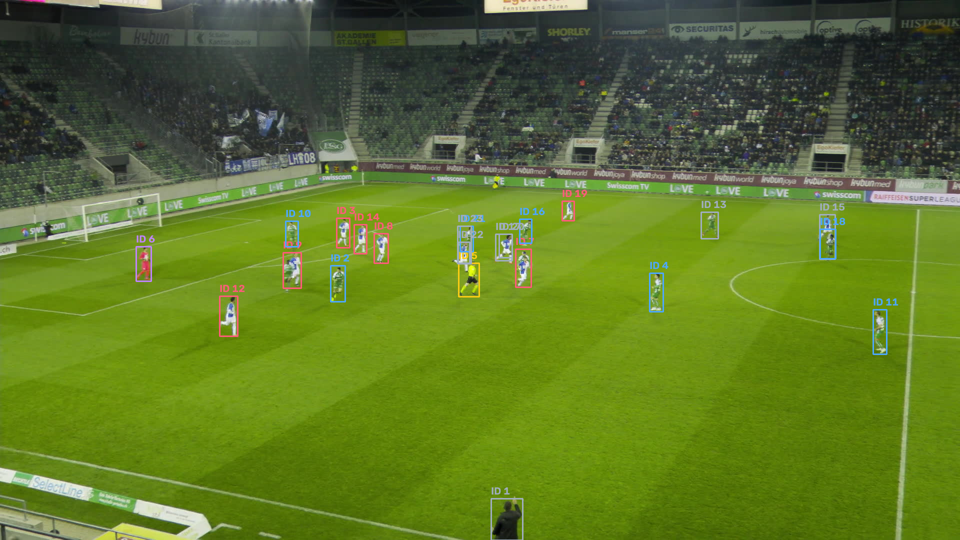


Testing image in a minimal Gradio application:
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [8]:
# ============================================================
# NOTEBOOK 5 — CELL 6A
# DIAGNOSE FOOTAGE DISPLAY
# ============================================================

from IPython.display import display
from PIL import Image
import numpy as np
import gradio as gr

test_frame = AVAILABLE_FRAMES[0]

print("Testing frame:", test_frame)
print("Frame path:", FRAME_FILES[test_frame])
print("File exists:", FRAME_FILES[test_frame].is_file())

raw_image = load_frame(test_frame)
annotated_image = render_match_frame(test_frame)

print("\nRaw image:")
print("Shape:", raw_image.shape)
print("Data type:", raw_image.dtype)

print("\nAnnotated image:")
print("Type:", type(annotated_image))
print("Size:", annotated_image.size)

print("\nDisplaying annotated frame directly in Colab:")

display(annotated_image.resize((960, 540)))

print("\nTesting image in a minimal Gradio application:")

with gr.Blocks() as image_test:
    gr.Markdown("## Football Frame Display Test")

    gr.Image(
        value=np.array(
            annotated_image.resize((960, 540))
        ),
        label="Match footage",
        type="numpy",
        interactive=False,
        height=540
    )

image_test.launch(
    share=False,
    debug=False
)

In [9]:
# ============================================================
# NOTEBOOK 5 — CELL 6B
# TEST GRADIO IMAGE THROUGH A PUBLIC LINK
# ============================================================

import gradio as gr
import numpy as np

test_frame = AVAILABLE_FRAMES[0]

# Use a smaller RGB image for reliable browser display
test_image = np.array(
    render_match_frame(test_frame).resize((960, 540)),
    dtype=np.uint8
)

print("Image shape:", test_image.shape)
print("Image type:", test_image.dtype)

with gr.Blocks(title="Football Vision Display Test") as display_test:

    gr.Markdown("# ⚽ Football Vision — Display Test")

    gr.Markdown(
        "The match footage should appear below."
    )

    gr.Image(
        value=test_image,
        type="numpy",
        label="Football footage",
        interactive=False,
        height=540,
        format="png"
    )

display_test.launch(
    share=True,
    inline=False,
    debug=True
)

Image shape: (540, 960, 3)
Image type: uint8
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f420094c55c3b39f6f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://f420094c55c3b39f6f.gradio.live


In [10]:
# ============================================================
# NOTEBOOK 5 — CELL 6C
# CLICKABLE FOOTBALL PLAYER SELECTION
# ============================================================

import gradio as gr
import numpy as np

DISPLAY_WIDTH = 960
DISPLAY_HEIGHT = 540

# ------------------------------------------------------------
# 1. RENDER FOOTAGE AT DISPLAY RESOLUTION
# ------------------------------------------------------------

def get_display_frame(frame_number, selected_id=None):

    image = render_match_frame(
        int(frame_number),
        selected_id=selected_id
    )

    image = image.resize(
        (DISPLAY_WIDTH, DISPLAY_HEIGHT)
    )

    return np.array(image, dtype=np.uint8)


# ------------------------------------------------------------
# 2. IDENTIFY CLICKED PLAYER
# ------------------------------------------------------------

def select_player(frame_number, evt: gr.SelectData):

    if evt.index is None:
        return gr.skip(), "No click coordinates received."

    click_x, click_y = map(int, evt.index[:2])

    # Original footage is 1920 × 1080.
    # Displayed footage is 960 × 540.
    original_height, original_width = load_frame(
        int(frame_number)
    ).shape[:2]

    original_x = click_x * original_width / DISPLAY_WIDTH
    original_y = click_y * original_height / DISPLAY_HEIGHT

    selected_id = find_player_at_click(
        int(frame_number),
        original_x,
        original_y
    )

    if selected_id is None:
        return (
            get_display_frame(frame_number),
            f"No player found at click position ({click_x}, {click_y})."
        )

    stats = player_stats[
        player_stats["track_id"] == selected_id
    ].iloc[0]

    information = (
        f"### Selected Player — ID {selected_id}\n\n"
        f"**Team:** {stats['team']}  \n"
        f"**Frames detected:** {stats['frames_detected']}  \n"
        f"**Detection confidence:** "
        f"{stats['mean_detection_confidence']:.2f}  \n"
        f"**Usable pitch observations:** "
        f"{stats['usable_pitch_observations']}  \n"
        f"**Accepted movement:** "
        f"{stats['estimated_distance']:.2f} pitch-reference units"
    )

    return (
        get_display_frame(frame_number, selected_id),
        information
    )


# ------------------------------------------------------------
# 3. UPDATE FRAME WHEN SLIDER CHANGES
# ------------------------------------------------------------

def change_frame(frame_number):

    return (
        get_display_frame(frame_number),
        "### Select a player\nClick a bounding box."
    )


# ------------------------------------------------------------
# 4. BUILD CLICKABLE TEST APPLICATION
# ------------------------------------------------------------

with gr.Blocks(
    title="Football Vision — Player Selection"
) as player_selection_test:

    gr.Markdown(
        "# ⚽ Football Vision — Interactive Player Selection\n"
        "Click a footballer to inspect their tracking information."
    )

    frame_slider = gr.Slider(
        minimum=min(AVAILABLE_FRAMES),
        maximum=max(AVAILABLE_FRAMES),
        value=min(AVAILABLE_FRAMES),
        step=1,
        label="Match frame"
    )

    footage = gr.Image(
        value=get_display_frame(min(AVAILABLE_FRAMES)),
        label="Click a player",
        type="numpy",
        interactive=False,
        height=540,
        format="png"
    )

    player_details = gr.Markdown(
        "### Select a player\nClick a bounding box."
    )

    footage.select(
        fn=select_player,
        inputs=[frame_slider],
        outputs=[footage, player_details]
    )

    frame_slider.change(
        fn=change_frame,
        inputs=[frame_slider],
        outputs=[footage, player_details]
    )


# ------------------------------------------------------------
# 5. LAUNCH IN EXTERNAL BROWSER
# ------------------------------------------------------------

player_selection_test.launch(
    share=True,
    inline=False,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1dd9f3258e1f6d5740.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://1dd9f3258e1f6d5740.gradio.live


In [12]:
# ============================================================
# NOTEBOOK 5 — CELL 7
# SYNCHRONIZED FOOTAGE AND TACTICAL PITCH
# ============================================================

import gradio as gr
import numpy as np

# ------------------------------------------------------------
# 1. PLAYER INFORMATION
# ------------------------------------------------------------

def get_player_information(selected_id, frame_number):

    if selected_id is None:
        return (
            "### No player selected\n"
            "Click a player in the footage or choose an ID."
        )

    stats_row = player_stats[
        player_stats["track_id"] == int(selected_id)
    ]

    if stats_row.empty:
        return "### Player not found"

    stats = stats_row.iloc[0]

    current = analytics_df[
        (analytics_df["frame"] == int(frame_number))
        & (analytics_df["track_id"] == int(selected_id))
    ]

    if current.empty:
        frame_status = "Not detected in this frame"
    elif bool(current.iloc[0]["usable_pitch_position"]):
        frame_status = "Tracked and pitch-mapped"
    else:
        frame_status = "Tracked; pitch position unavailable"

    return (
        f"### Player ID {selected_id}\n\n"
        f"**Team:** {stats['team']}  \n"
        f"**Current frame:** {frame_status}  \n"
        f"**Frames detected:** {stats['frames_detected']}  \n"
        f"**Tracking coverage:** {stats['tracking_coverage_pct']}%  \n"
        f"**Mean detection confidence:** "
        f"{stats['mean_detection_confidence']:.2f}  \n"
        f"**Usable pitch observations:** "
        f"{stats['usable_pitch_observations']}  \n"
        f"**Accepted movement:** "
        f"{stats['estimated_distance']:.2f} pitch-reference units"
    )


# ------------------------------------------------------------
# 2. UPDATE BOTH VISUALIZATIONS
# ------------------------------------------------------------

def update_views(frame_number, selected_id):

    frame_number = int(frame_number)

    selected_id = (
        int(selected_id)
        if selected_id is not None
        else None
    )

    footage_image = get_display_frame(
        frame_number,
        selected_id
    )

    pitch_figure = make_pitch_figure(
        frame_number,
        selected_id=selected_id,
        show_trails=True
    )

    information = get_player_information(
        selected_id,
        frame_number
    )

    return footage_image, pitch_figure, information


# ------------------------------------------------------------
# 3. CLICK FOOTAGE TO SELECT PLAYER
# ------------------------------------------------------------

def select_from_footage(frame_number, evt: gr.SelectData):

    if evt.index is None:
        return gr.skip(), gr.skip(), gr.skip(), gr.skip(), gr.skip()

    click_x, click_y = map(int, evt.index[:2])

    original_height, original_width = load_frame(
        int(frame_number)
    ).shape[:2]

    original_x = click_x * original_width / DISPLAY_WIDTH
    original_y = click_y * original_height / DISPLAY_HEIGHT

    selected_id = find_player_at_click(
        int(frame_number),
        original_x,
        original_y
    )

    if selected_id is None:
        return gr.skip(), gr.skip(), gr.skip(), gr.skip(), gr.skip()

    image, pitch, information = update_views(
        frame_number,
        selected_id
    )

    return (
        selected_id,
        str(selected_id),
        image,
        pitch,
        information
    )


# ------------------------------------------------------------
# 4. SELECT PLAYER FROM DROPDOWN
# ------------------------------------------------------------

def select_from_dropdown(frame_number, player_id):

    selected_id = (
        int(player_id)
        if player_id not in (None, "")
        else None
    )

    image, pitch, information = update_views(
        frame_number,
        selected_id
    )

    return selected_id, image, pitch, information


# ------------------------------------------------------------
# 5. CHANGE FRAME WHILE PRESERVING SELECTION
# ------------------------------------------------------------

def change_dashboard_frame(frame_number, selected_id):

    return update_views(
        frame_number,
        selected_id
    )


# ------------------------------------------------------------
# 6. BUILD SYNCHRONIZED TEST APPLICATION
# ------------------------------------------------------------

player_choices = [
    str(int(track_id))
    for track_id in sorted(
        player_stats["track_id"].unique()
    )
]

initial_frame = AVAILABLE_FRAMES[0]

with gr.Blocks(
    title="Football Vision — Synchronized Analytics"
) as synchronized_demo:

    selected_player_state = gr.State(None)

    gr.Markdown(
        "# ⚽ Football Vision Analytics\n"
        "### Synchronized Match Footage and Tactical Pitch"
    )

    with gr.Row():

        frame_slider = gr.Slider(
            minimum=min(AVAILABLE_FRAMES),
            maximum=max(AVAILABLE_FRAMES),
            value=initial_frame,
            step=1,
            label="Match frame"
        )

        player_dropdown = gr.Dropdown(
            choices=player_choices,
            value=None,
            label="Select tracking ID",
            interactive=True
        )

    with gr.Row():

        with gr.Column(scale=3):

            footage_view = gr.Image(
                value=get_display_frame(initial_frame),
                label="Match footage — click a player",
                type="numpy",
                interactive=False,
                height=480,
                format="png"
            )

        with gr.Column(scale=2):

            pitch_view = gr.Plot(
                value=make_pitch_figure(initial_frame),
                label="Tactical pitch"
            )

    player_info = gr.Markdown(
        "### No player selected\n"
        "Click a player in the footage or choose an ID."
    )

    # Footage click -> update selected ID and both views
    footage_view.select(
        fn=select_from_footage,
        inputs=[frame_slider],
        outputs=[
            selected_player_state,
            player_dropdown,
            footage_view,
            pitch_view,
            player_info
        ]
    )

    # Dropdown -> update selected ID and both views
    player_dropdown.change(
        fn=select_from_dropdown,
        inputs=[frame_slider, player_dropdown],
        outputs=[
            selected_player_state,
            footage_view,
            pitch_view,
            player_info
        ]
    )

    # Frame change -> preserve selected ID
    frame_slider.change(
        fn=change_dashboard_frame,
        inputs=[frame_slider, selected_player_state],
        outputs=[
            footage_view,
            pitch_view,
            player_info
        ]
    )

# ------------------------------------------------------------
# 7. LAUNCH
# ------------------------------------------------------------

synchronized_demo.launch(
    share=True,
    inline=False,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3a48b849eb10a16d1a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://3a48b849eb10a16d1a.gradio.live


In [13]:
# ============================================================
# NOTEBOOK 5 — CELL 8
# IMPROVE PITCH VISUALIZATION AND CALIBRATION STATUS
# ============================================================

import plotly.graph_objects as go
import numpy as np

# Preserve original function for reference
make_pitch_figure_v1 = make_pitch_figure


def make_pitch_figure(
    frame_number,
    selected_id=None,
    show_trails=True
):
    frame_number = int(frame_number)

    fig = go.Figure()

    current = analytics_df[
        (analytics_df["frame"] == frame_number)
        & analytics_df["usable_pitch_position"]
    ]

    # --------------------------------------------------------
    # 1. MOVEMENT TRAILS
    # --------------------------------------------------------

    if show_trails and not current.empty:

        history = analytics_df[
            (analytics_df["frame"] >= frame_number - 25)
            & (analytics_df["frame"] <= frame_number)
            & analytics_df["usable_pitch_position"]
        ]

        for track_id, player in history.groupby("track_id"):

            player = player.sort_values("frame")

            # Build separate lines when there is a gap
            segment = []

            def draw_segment(rows):
                if len(rows) < 2:
                    return

                fig.add_trace(go.Scatter(
                    x=[r.pitch_x for r in rows],
                    y=[r.pitch_y for r in rows],
                    mode="lines",
                    line=dict(
                        color=TEAM_COLORS.get(
                            rows[-1].team,
                            TEAM_COLORS["Unknown"]
                        ),
                        width=4 if track_id == selected_id else 1.5
                    ),
                    opacity=(
                        0.95 if track_id == selected_id else 0.3
                    ),
                    hoverinfo="skip",
                    showlegend=False
                ))

            for row in player.itertuples():

                if segment and not bool(row.valid_step):
                    draw_segment(segment)
                    segment = []

                segment.append(row)

            draw_segment(segment)

    # --------------------------------------------------------
    # 2. PLAYER MARKERS
    # --------------------------------------------------------

    if not current.empty:

        for team, players in current.groupby("team"):

            for row in players.itertuples():

                selected = row.track_id == selected_id

                fig.add_trace(go.Scatter(
                    x=[row.pitch_x],
                    y=[row.pitch_y],
                    mode="markers+text",
                    text=[str(row.track_id)],
                    textposition="top center",
                    textfont=dict(
                        color="white",
                        size=11
                    ),
                    marker=dict(
                        size=21 if selected else 12,
                        color=TEAM_COLORS.get(
                            team,
                            TEAM_COLORS["Unknown"]
                        ),
                        line=dict(
                            color=(
                                THEME["selected"]
                                if selected else "#FFFFFF"
                            ),
                            width=4 if selected else 1
                        )
                    ),
                    customdata=[int(row.track_id)],
                    hovertemplate=(
                        "Track ID: %{customdata}"
                        "<br>X: %{x:.1f}"
                        "<br>Y: %{y:.1f}"
                        "<extra></extra>"
                    ),
                    showlegend=False
                ))

    # --------------------------------------------------------
    # 3. UNAVAILABLE CALIBRATION MESSAGE
    # --------------------------------------------------------

    if current.empty:

        fig.add_annotation(
            x=PITCH_LENGTH / 2,
            y=PITCH_WIDTH / 2,
            text=(
                "<b>PITCH CALIBRATION UNAVAILABLE</b>"
                "<br><br>"
                f"Frame {frame_number} has no usable "
                "pitch positions."
                "<br>"
                "Player tracking remains available "
                "in the footage."
            ),
            showarrow=False,
            font=dict(
                color="#FFFFFF",
                size=15
            ),
            bgcolor="rgba(8,15,29,0.88)",
            bordercolor=THEME["accent"],
            borderwidth=1,
            borderpad=15,
            align="center"
        )

    # --------------------------------------------------------
    # 4. LAYOUT
    # --------------------------------------------------------

    fig.update_layout(
        title=dict(
            text=f"TACTICAL PITCH · FRAME {frame_number}",
            font=dict(
                color=THEME["text"],
                size=16
            )
        ),
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["pitch"],
        font=dict(color=THEME["text"]),
        shapes=pitch_shapes(),
        xaxis=dict(
            range=[-3, PITCH_LENGTH + 3],
            visible=False,
            fixedrange=True
        ),
        yaxis=dict(
            range=[-3, PITCH_WIDTH + 3],
            visible=False,
            scaleanchor="x",
            scaleratio=1,
            fixedrange=True
        ),
        margin=dict(l=12, r=12, t=50, b=12),
        height=520,
        showlegend=False,
        uirevision="pitch"
    )

    return fig


# ------------------------------------------------------------
# 5. TEST BOTH FRAME TYPES
# ------------------------------------------------------------

print("Testing calibrated frame 350:")
display(make_pitch_figure(350, selected_id=3))

print("\nTesting uncalibrated frame 400:")
display(make_pitch_figure(400, selected_id=3))

print("\nPitch visualization update successful!")

Testing calibrated frame 350:



Testing uncalibrated frame 400:



Pitch visualization update successful!


In [14]:
# ============================================================
# NOTEBOOK 5 — CELL 9
# CALIBRATION AND TRACKING STATUS
# ============================================================

def get_frame_status(frame_number):

    frame_number = int(frame_number)

    current = analytics_df[
        analytics_df["frame"] == frame_number
    ]

    if current.empty:
        return (
            "### Frame unavailable\n"
            "No tracking observations found."
        )

    tracked = current["track_id"].nunique()

    mapped = int(
        current["usable_pitch_position"].sum()
    )

    calibrated = bool(
        current["calibration_available"].any()
    )

    if mapped > 0:
        status = "🟢 Pitch mapping available"
    elif calibrated:
        status = "🟠 Calibration exists, but no usable player positions"
    else:
        status = "🔴 Pitch calibration unavailable"

    return (
        f"### Frame {frame_number}\n\n"
        f"**Status:** {status}  \n"
        f"**Tracked IDs:** {tracked}  \n"
        f"**Usable pitch positions:** {mapped}  \n"
        f"**Tracker:** {config['tracking']['name']}  \n"
        f"**Calibration version:** {config['calibration']['version']}"
    )


print("FRAME 350")
print(get_frame_status(350))

print("\n" + "=" * 50)

print("FRAME 400")
print(get_frame_status(400))

FRAME 350
### Frame 350

**Status:** 🟢 Pitch mapping available  
**Tracked IDs:** 23  
**Usable pitch positions:** 18  
**Tracker:** ByteTrack  
**Calibration version:** v2.0/smoothed_hybrid

FRAME 400
### Frame 400

**Status:** 🔴 Pitch calibration unavailable  
**Tracked IDs:** 20  
**Usable pitch positions:** 0  
**Tracker:** ByteTrack  
**Calibration version:** v2.0/smoothed_hybrid


In [15]:
# ============================================================
# NOTEBOOK 5 — CELL 10
# REUSABLE FOOTBALL ANALYTICS CHARTS
# ============================================================

import plotly.graph_objects as go
import numpy as np

def empty_chart(message, title):
    fig = go.Figure()

    fig.add_annotation(
        x=0.5, y=0.5,
        xref="paper", yref="paper",
        text=message,
        showarrow=False,
        font=dict(size=15, color=THEME["muted"])
    )

    fig.update_layout(
        title=title,
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["surface"],
        font=dict(color=THEME["text"]),
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        height=350,
        margin=dict(l=30, r=20, t=55, b=30)
    )

    return fig


# ------------------------------------------------------------
# 1. PLAYER TRAJECTORY
# ------------------------------------------------------------

def make_trajectory_chart(selected_id):

    if selected_id is None:
        return empty_chart(
            "Select a player to view their trajectory",
            "PLAYER MOVEMENT"
        )

    player = analytics_df[
        (analytics_df["track_id"] == int(selected_id))
        & analytics_df["usable_pitch_position"]
    ].sort_values("frame")

    if player.empty:
        return empty_chart(
            "No usable pitch positions for this tracking ID",
            "PLAYER MOVEMENT"
        )

    fig = go.Figure()

    # Draw accepted consecutive movement segments only
    for i in range(1, len(player)):
        previous = player.iloc[i - 1]
        current = player.iloc[i]

        if (
            int(current["frame"]) == int(previous["frame"]) + 1
            and bool(current["valid_step"])
        ):
            fig.add_trace(go.Scatter(
                x=[previous["pitch_x"], current["pitch_x"]],
                y=[previous["pitch_y"], current["pitch_y"]],
                mode="lines",
                line=dict(color=THEME["accent"], width=3),
                hoverinfo="skip",
                showlegend=False
            ))

    fig.add_trace(go.Scatter(
        x=player["pitch_x"],
        y=player["pitch_y"],
        mode="markers",
        marker=dict(
            color=player["frame"],
            colorscale="Viridis",
            size=8,
            colorbar=dict(title="Frame")
        ),
        customdata=player["frame"],
        hovertemplate=(
            "Frame %{customdata}"
            "<br>X: %{x:.2f}"
            "<br>Y: %{y:.2f}"
            "<extra></extra>"
        ),
        showlegend=False
    ))

    fig.update_layout(
        title=f"PLAYER MOVEMENT · ID {selected_id}",
        shapes=pitch_shapes(),
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["pitch"],
        font=dict(color=THEME["text"]),
        xaxis=dict(
            range=[-3, PITCH_LENGTH + 3],
            visible=False
        ),
        yaxis=dict(
            range=[-3, PITCH_WIDTH + 3],
            visible=False,
            scaleanchor="x",
            scaleratio=1
        ),
        height=350,
        margin=dict(l=15, r=15, t=55, b=15)
    )

    return fig


# ------------------------------------------------------------
# 2. PLAYER POSITION HEATMAP
# ------------------------------------------------------------

def make_heatmap_chart(selected_id):

    if selected_id is None:
        return empty_chart(
            "Select a player to view their heatmap",
            "POSITION HEATMAP"
        )

    player = analytics_df[
        (analytics_df["track_id"] == int(selected_id))
        & analytics_df["usable_pitch_position"]
    ]

    if player.empty:
        return empty_chart(
            "No usable pitch positions for this tracking ID",
            "POSITION HEATMAP"
        )

    x = player["pitch_x"].to_numpy(dtype=float)
    y = player["pitch_y"].to_numpy(dtype=float)

    # Bin observations into a pitch grid
    heat, x_edges, y_edges = np.histogram2d(
        x, y,
        bins=[21, 14],
        range=[
            [0, PITCH_LENGTH],
            [0, PITCH_WIDTH]
        ]
    )

    fig = go.Figure()

    fig.add_trace(go.Heatmap(
        x=(x_edges[:-1] + x_edges[1:]) / 2,
        y=(y_edges[:-1] + y_edges[1:]) / 2,
        z=heat.T,
        colorscale="Turbo",
        showscale=True,
        colorbar=dict(title="Observations"),
        hovertemplate=(
            "X: %{x:.1f}"
            "<br>Y: %{y:.1f}"
            "<br>Observations: %{z:.0f}"
            "<extra></extra>"
        )
    ))

    fig.update_layout(
        title=f"POSITION HEATMAP · ID {selected_id}",
        shapes=pitch_shapes(),
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["pitch"],
        font=dict(color=THEME["text"]),
        xaxis=dict(
            range=[0, PITCH_LENGTH],
            visible=False
        ),
        yaxis=dict(
            range=[0, PITCH_WIDTH],
            visible=False,
            scaleanchor="x",
            scaleratio=1
        ),
        height=350,
        margin=dict(l=15, r=15, t=55, b=15)
    )

    return fig


# ------------------------------------------------------------
# 3. TEAM OBSERVATION COMPARISON
# ------------------------------------------------------------

def make_team_chart():

    usable = analytics_df[
        analytics_df["usable_pitch_position"]
    ]

    counts = (
        usable.groupby("team")
        .size()
        .sort_values(ascending=False)
    )

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=counts.index.tolist(),
        y=counts.values.tolist(),
        marker_color=[
            TEAM_COLORS.get(team, TEAM_COLORS["Unknown"])
            for team in counts.index
        ],
        text=counts.values,
        textposition="outside"
    ))

    fig.update_layout(
        title="USABLE PITCH OBSERVATIONS BY TEAM",
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["surface"],
        font=dict(color=THEME["text"]),
        yaxis_title="Observations",
        height=350,
        margin=dict(l=45, r=20, t=55, b=60)
    )

    return fig


# ------------------------------------------------------------
# 4. TEST ALL THREE CHARTS
# ------------------------------------------------------------

print("Testing player trajectory...")
display(make_trajectory_chart(3))

print("Testing player heatmap...")
display(make_heatmap_chart(3))

print("Testing team comparison...")
display(make_team_chart())

print("\nAll three analytics charts generated successfully!")

Testing player trajectory...


Testing player heatmap...


Testing team comparison...



All three analytics charts generated successfully!


In [16]:
# ============================================================
# NOTEBOOK 5 — CELL 11
# FOOTBALL VISION ANALYTICS STUDIO — INTEGRATED DASHBOARD
# ============================================================

import gradio as gr

# ------------------------------------------------------------
# 1. DASHBOARD THEME
# ------------------------------------------------------------

dashboard_css = """
.gradio-container {
    background: #080F1D !important;
    color: #F4F7FB !important;
    max-width: 1600px !important;
    margin: auto !important;
}

#studio-header {
    padding: 20px 24px;
    border: 1px solid #25354B;
    border-radius: 16px;
    background: linear-gradient(110deg, #14243B, #0B1627);
}

#studio-header h1 {
    color: #F4F7FB !important;
    font-size: 30px !important;
}

#studio-header p {
    color: #94A3B8 !important;
}

#dashboard-status {
    border: 1px solid #25354B;
    border-radius: 12px;
    padding: 12px;
}

footer {
    display: none !important;
}
"""

# ------------------------------------------------------------
# 2. DASHBOARD CALLBACKS
# ------------------------------------------------------------

def dashboard_update(frame_number, selected_id):
    """Update all frame-dependent components."""

    image, pitch, info = update_views(
        frame_number,
        selected_id
    )

    status = get_frame_status(frame_number)

    return image, pitch, info, status


def dashboard_player_click(frame_number, evt: gr.SelectData):
    """Select a player from footage."""

    if evt.index is None:
        return (
            gr.skip(), gr.skip(), gr.skip(),
            gr.skip(), gr.skip(), gr.skip(), gr.skip()
        )

    click_x, click_y = map(int, evt.index[:2])

    height, width = load_frame(int(frame_number)).shape[:2]

    original_x = click_x * width / DISPLAY_WIDTH
    original_y = click_y * height / DISPLAY_HEIGHT

    selected_id = find_player_at_click(
        int(frame_number),
        original_x,
        original_y
    )

    if selected_id is None:
        return (
            gr.skip(), gr.skip(), gr.skip(),
            gr.skip(), gr.skip(), gr.skip(), gr.skip()
        )

    image, pitch, info, status = dashboard_update(
        frame_number,
        selected_id
    )

    return (
        selected_id,
        str(selected_id),
        image,
        pitch,
        info,
        status,
        make_trajectory_chart(selected_id)
    )


def dashboard_dropdown_change(frame_number, player_id):

    selected_id = int(player_id) if player_id else None

    image, pitch, info, status = dashboard_update(
        frame_number,
        selected_id
    )

    return (
        selected_id,
        image,
        pitch,
        info,
        status,
        make_trajectory_chart(selected_id),
        make_heatmap_chart(selected_id)
    )


def dashboard_frame_change(frame_number, selected_id):

    image, pitch, info, status = dashboard_update(
        frame_number,
        selected_id
    )

    return image, pitch, info, status


# ------------------------------------------------------------
# 3. INITIAL VALUES
# ------------------------------------------------------------

initial_frame = min(AVAILABLE_FRAMES)

player_choices = [
    str(int(track_id))
    for track_id in sorted(player_stats["track_id"].unique())
]

# ------------------------------------------------------------
# 4. BUILD DASHBOARD
# ------------------------------------------------------------

with gr.Blocks(
    title="Football Vision Analytics Studio",
    css=dashboard_css,
    theme=gr.themes.Base()
) as football_studio:

    selected_player = gr.State(None)

    gr.Markdown(
        """
        # ⚽ FOOTBALL VISION ANALYTICS STUDIO

        **Computer Vision-Based Football Player Tracking and Movement Analysis**

        SoccerNet · SNMOT-066 · ByteTrack
        """,
        elem_id="studio-header"
    )

    # --------------------------------------------------------
    # CONTROLS
    # --------------------------------------------------------

    with gr.Row():

        frame_control = gr.Slider(
            minimum=min(AVAILABLE_FRAMES),
            maximum=max(AVAILABLE_FRAMES),
            value=initial_frame,
            step=1,
            label="Match frame",
            scale=4
        )

        player_control = gr.Dropdown(
            choices=player_choices,
            value=None,
            label="Tracking ID",
            scale=1
        )

    # --------------------------------------------------------
    # MAIN VIEW
    # --------------------------------------------------------

    with gr.Tab("⚽ Match Analysis"):

        with gr.Row():

            with gr.Column(scale=3):

                match_footage = gr.Image(
                    value=get_display_frame(initial_frame),
                    label="Match footage — click a player",
                    type="numpy",
                    interactive=False,
                    height=480,
                    format="png"
                )

            with gr.Column(scale=2):

                tactical_pitch = gr.Plot(
                    value=make_pitch_figure(initial_frame),
                    label="Tactical pitch"
                )

        with gr.Row():

            with gr.Column():

                player_panel = gr.Markdown(
                    get_player_information(None, initial_frame)
                )

            with gr.Column():

                frame_panel = gr.Markdown(
                    get_frame_status(initial_frame),
                    elem_id="dashboard-status"
                )

    # --------------------------------------------------------
    # PLAYER ANALYTICS
    # --------------------------------------------------------

    with gr.Tab("📈 Player Analytics"):

        with gr.Row():

            trajectory_plot = gr.Plot(
                value=make_trajectory_chart(None),
                label="Player trajectory"
            )

            heatmap_plot = gr.Plot(
                value=make_heatmap_chart(None),
                label="Position heatmap"
            )

    # --------------------------------------------------------
    # TEAM ANALYTICS
    # --------------------------------------------------------

    with gr.Tab("📊 Team Analytics"):

        team_plot = gr.Plot(
            value=make_team_chart(),
            label="Team observation comparison"
        )

        gr.Markdown(
            """
            **Interpretation:** This chart counts usable pitch
            observations, not unique players, possession,
            or team performance.
            """
        )

    # --------------------------------------------------------
    # DATA QUALITY
    # --------------------------------------------------------

    with gr.Tab("🔬 Data Quality"):

        gr.Markdown(
            """
            ### Tracking and Calibration Quality

            **Tracking:** Frames 350–450

            **Pitch mapping:** Frames 350–379

            **Tracker:** ByteTrack

            **Calibration:** v2.0 / smoothed hybrid

            **Important:** Track IDs can change when players are
            occluded or the camera view changes. Distances are
            expressed in pitch-reference units and should not
            yet be interpreted as validated physical measurements.
            """
        )

    # --------------------------------------------------------
    # EVENTS
    # --------------------------------------------------------

    match_footage.select(
        fn=dashboard_player_click,
        inputs=[frame_control],
        outputs=[
            selected_player,
            player_control,
            match_footage,
            tactical_pitch,
            player_panel,
            frame_panel,
            trajectory_plot
        ]
    )

    player_control.change(
        fn=dashboard_dropdown_change,
        inputs=[frame_control, player_control],
        outputs=[
            selected_player,
            match_footage,
            tactical_pitch,
            player_panel,
            frame_panel,
            trajectory_plot,
            heatmap_plot
        ]
    )

    frame_control.change(
        fn=dashboard_frame_change,
        inputs=[frame_control, selected_player],
        outputs=[
            match_footage,
            tactical_pitch,
            player_panel,
            frame_panel
        ]
    )

# ------------------------------------------------------------
# 5. LAUNCH APPLICATION
# ------------------------------------------------------------

# Disabled development launch: football_studio
# football_studio.launch(
#     share=True,
#     inline=False,
#     debug=True
# )

/tmp/ipykernel_513/288360800.py:153: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Testing frame navigation:
Previous from 400: 399
Next from 400: 401

Testing filtered footage:


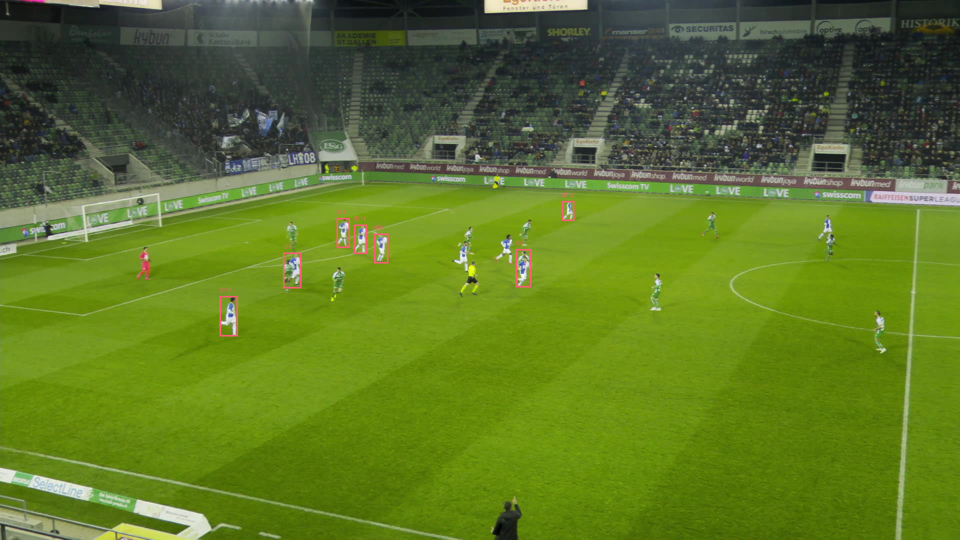


Testing filtered tactical pitch:



Cell 12A completed successfully!


In [17]:
# ============================================================
# NOTEBOOK 5 — CELL 12A
# FRAME NAVIGATION AND VISUALIZATION FILTERS
# ============================================================

import gradio as gr
import numpy as np
from PIL import Image, ImageDraw, ImageFont

# ------------------------------------------------------------
# 1. FILTERED FOOTAGE
# ------------------------------------------------------------

def render_filtered_frame(
    frame_number,
    selected_id=None,
    team_filter="All",
    show_boxes=True,
    show_ids=True
):
    frame_number = int(frame_number)

    # Start with the original footage, without annotations.
    image = Image.fromarray(load_frame(frame_number).copy())
    draw = ImageDraw.Draw(image)

    current = analytics_df[
        analytics_df["frame"] == frame_number
    ]

    if team_filter != "All":
        current = current[current["team"] == team_filter]

    for row in current.itertuples():

        track_id = int(row.track_id)
        selected = track_id == selected_id

        color = (
            THEME["selected"]
            if selected
            else TEAM_COLORS.get(
                row.team,
                TEAM_COLORS["Unknown"]
            )
        )

        x1, y1, x2, y2 = map(
            int,
            [row.x1, row.y1, row.x2, row.y2]
        )

        if show_boxes:
            draw.rectangle(
                [x1, y1, x2, y2],
                outline=color,
                width=5 if selected else 3
            )

        if show_ids:
            draw.text(
                (x1, max(0, y1 - 18)),
                f"ID {track_id}",
                fill=color
            )

    image = image.resize((DISPLAY_WIDTH, DISPLAY_HEIGHT))

    return np.array(image, dtype=np.uint8)


# ------------------------------------------------------------
# 2. FRAME NAVIGATION
# ------------------------------------------------------------

def previous_frame(frame_number):
    frame_number = int(frame_number)
    available = [f for f in AVAILABLE_FRAMES if f < frame_number]

    return available[-1] if available else frame_number


def next_frame(frame_number):
    frame_number = int(frame_number)
    available = [f for f in AVAILABLE_FRAMES if f > frame_number]

    return available[0] if available else frame_number


# ------------------------------------------------------------
# 3. FILTERED PITCH
# ------------------------------------------------------------

def make_filtered_pitch(
    frame_number,
    selected_id=None,
    team_filter="All",
    show_trails=True
):
    # Use our existing pitch visualization engine.
    fig = make_pitch_figure(
        frame_number,
        selected_id=selected_id,
        show_trails=show_trails
    )

    # Hide traces belonging to other teams.
    # Each player marker is a separate trace in Cell 8.
    if team_filter != "All":

        current = analytics_df[
            (analytics_df["frame"] == int(frame_number))
            & analytics_df["usable_pitch_position"]
        ]

        allowed_ids = set(
            current[current["team"] == team_filter]["track_id"]
        )

        # Filter marker traces using their stored tracking ID.
        for trace in fig.data:

            if getattr(trace, "customdata", None) is not None:

                try:
                    track_id = int(trace.customdata[0])

                    if track_id not in allowed_ids:
                        trace.visible = False

                except (ValueError, TypeError, IndexError):
                    pass

    return fig


# ------------------------------------------------------------
# 4. COMBINED UPDATE
# ------------------------------------------------------------

def filtered_dashboard_update(
    frame_number,
    selected_id,
    team_filter,
    show_boxes,
    show_ids,
    show_trails
):
    frame_number = int(frame_number)

    image = render_filtered_frame(
        frame_number,
        selected_id,
        team_filter,
        show_boxes,
        show_ids
    )

    pitch = make_filtered_pitch(
        frame_number,
        selected_id,
        team_filter,
        show_trails
    )

    return image, pitch, get_frame_status(frame_number)


# ------------------------------------------------------------
# 5. TEST FILTER FUNCTIONS
# ------------------------------------------------------------

print("Testing frame navigation:")
print("Previous from 400:", previous_frame(400))
print("Next from 400:", next_frame(400))

print("\nTesting filtered footage:")
display(
    Image.fromarray(
        render_filtered_frame(
            350,
            team_filter="Team_A",
            show_boxes=True,
            show_ids=True
        )
    )
)

print("\nTesting filtered tactical pitch:")
display(
    make_filtered_pitch(
        350,
        team_filter="Team_A",
        show_trails=False
    )
)

print("\nCell 12A completed successfully!")

FRAME 350 — CLASSIFICATION SUMMARY

Predicted categories:
team
Unknown               7
Team_B                7
Team_A                7
Referee               1
Goalkeeper_Unknown    1

Individual tracking observations:


,track_id,team,x1,y1,x2,y2,confidence
0,6,Goalkeeper_Unknown,272.745300,493.646973,302.422119,562.294434,0.740875
1,5,Referee,917.019287,526.063354,958.692139,593.260376,0.747788
2,3,Team_A,673.481445,436.325378,699.268311,495.559631,0.766287
3,7,Team_A,1031.315552,498.032837,1062.393433,574.428101,0.707775
4,8,Team_A,748.409912,467.605103,776.282227,526.552002,0.683292
5,9,Team_A,566.880127,505.991638,602.002441,576.921082,0.682278
6,12,Team_A,439.749451,592.351807,475.840149,672.609009,0.620258
7,14,Team_A,708.340820,449.844238,733.973633,507.831909,0.597409
8,19,Team_A,1124.424927,402.553467,1148.748901,441.656128,0.454764
9,2,Team_B,661.884888,531.809570,690.140137,603.702881,0.771774


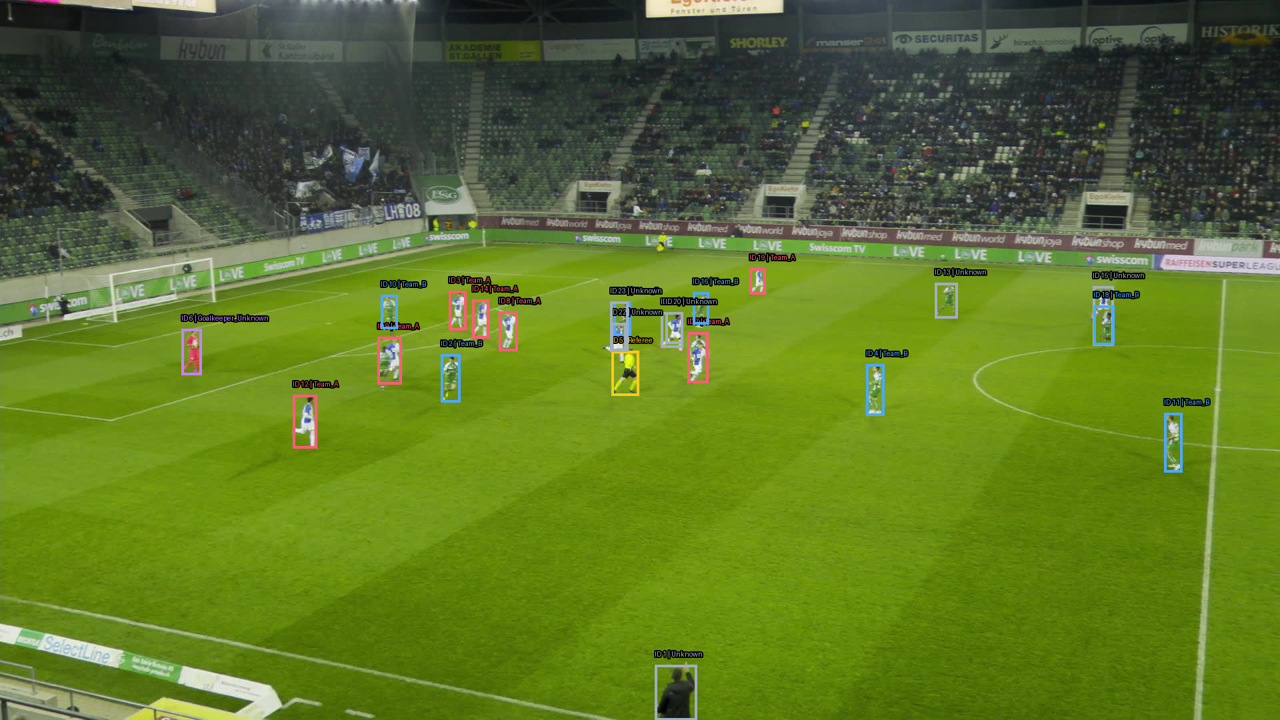


Diagnostic completed.


In [18]:
# ============================================================
# NOTEBOOK 5 — CELL 12B
# TEAM CLASSIFICATION DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np
from PIL import Image, ImageDraw

TEST_FRAME = 350

# Get all detected players in this frame
frame_data = analytics_df[
    analytics_df["frame"] == TEST_FRAME
].copy()

print(f"FRAME {TEST_FRAME} — CLASSIFICATION SUMMARY")
print("=" * 55)

print("\nPredicted categories:")
print(frame_data["team"].value_counts().to_string())

print("\nIndividual tracking observations:")

columns_to_show = [
    "track_id",
    "team",
    "x1",
    "y1",
    "x2",
    "y2"
]

if "confidence" in frame_data.columns:
    columns_to_show.append("confidence")

display(
    frame_data[columns_to_show]
    .sort_values(["team", "track_id"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# DRAW ALL DETECTED PLAYERS WITH THEIR PREDICTED TEAM
# ------------------------------------------------------------

image = Image.fromarray(load_frame(TEST_FRAME).copy())
draw = ImageDraw.Draw(image)

for row in frame_data.itertuples():

    x1, y1, x2, y2 = map(
        int,
        [row.x1, row.y1, row.x2, row.y2]
    )

    color = TEAM_COLORS.get(
        row.team,
        TEAM_COLORS["Unknown"]
    )

    draw.rectangle(
        [x1, y1, x2, y2],
        outline=color,
        width=4
    )

    label = f"ID {int(row.track_id)} | {row.team}"

    draw.text(
        (x1, max(0, y1 - 22)),
        label,
        fill=color,
        stroke_width=2,
        stroke_fill="black"
    )

display(image.resize((1280, 720)))

print("\nDiagnostic completed.")

In [19]:
# ============================================================
# NOTEBOOK 5 — CELL 12C
# HUMAN-REVIEWED TEAM CORRECTIONS
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. STORE VERIFIED CORRECTIONS
# ------------------------------------------------------------

team_corrections = pd.DataFrame([
    {"frame": 350, "track_id": 22, "reviewed_team": "Team_A"},
    {"frame": 350, "track_id": 20, "reviewed_team": "Team_A"},
    {"frame": 350, "track_id": 15, "reviewed_team": "Team_A"},
    {"frame": 350, "track_id": 23, "reviewed_team": "Team_B"},
    {"frame": 350, "track_id": 13, "reviewed_team": "Team_B"},
])

# ------------------------------------------------------------
# 2. PRESERVE ORIGINAL MODEL PREDICTIONS
# ------------------------------------------------------------

reviewed_df = analytics_df.copy()

reviewed_df["model_team"] = reviewed_df["team"]

reviewed_df = reviewed_df.merge(
    team_corrections,
    on=["frame", "track_id"],
    how="left",
    validate="many_to_one"
)

reviewed_df["display_team"] = reviewed_df[
    "reviewed_team"
].fillna(reviewed_df["model_team"])

reviewed_df["team_label_source"] = (
    reviewed_df["reviewed_team"]
    .notna()
    .map({
        True: "Human reviewed",
        False: "Model prediction"
    })
)

# ------------------------------------------------------------
# 3. VERIFY THE CORRECTIONS
# ------------------------------------------------------------

frame_350 = reviewed_df[
    reviewed_df["frame"] == 350
]

print("ORIGINAL MODEL PREDICTIONS")
print(frame_350["model_team"].value_counts())

print("\nAFTER HUMAN REVIEW")
print(frame_350["display_team"].value_counts())

print("\nCORRECTED OBSERVATIONS")

display(
    frame_350[
        frame_350["team_label_source"] == "Human reviewed"
    ][[
        "frame",
        "track_id",
        "model_team",
        "display_team",
        "team_label_source"
    ]]
)

# ------------------------------------------------------------
# 4. SAVE CORRECTIONS SEPARATELY
# ------------------------------------------------------------

correction_path = APP_DIR / "human_reviewed_team_labels.csv"

team_corrections.to_csv(
    correction_path,
    index=False
)

print("\nSaved corrections to:")
print(correction_path)

print("\nCell 12C completed successfully!")

ORIGINAL MODEL PREDICTIONS
model_team
Unknown               7
Team_B                7
Team_A                7
Referee               1
Goalkeeper_Unknown    1
Name: count, dtype: int64

AFTER HUMAN REVIEW
display_team
Team_A                10
Team_B                 9
Unknown                2
Referee                1
Goalkeeper_Unknown     1
Name: count, dtype: int64

CORRECTED OBSERVATIONS


,frame,track_id,model_team,display_team,team_label_source
1086,350,13,Unknown,Team_B,Human reviewed
1284,350,15,Unknown,Team_A,Human reviewed
1516,350,20,Unknown,Team_A,Human reviewed
1542,350,22,Unknown,Team_A,Human reviewed
1549,350,23,Unknown,Team_B,Human reviewed



Saved corrections to:
/content/drive/MyDrive/Football_CV_Project/outputs/notebook5/application/SNMOT-066/human_reviewed_team_labels.csv

Cell 12C completed successfully!


Testing Team A after human review...


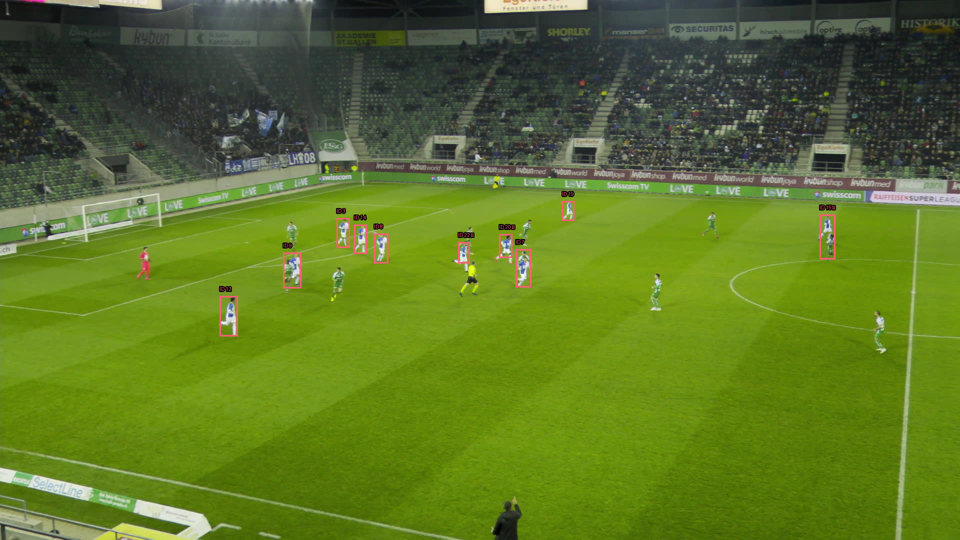

Expected Team A detections: 10

Cell 12D completed successfully!


In [20]:
# ============================================================
# NOTEBOOK 5 — CELL 12D
# REVIEWED TEAM LABELS + ACCURATE VISUALIZATION FILTERS
# ============================================================

from PIL import Image, ImageDraw
import numpy as np
import plotly.graph_objects as go

# ------------------------------------------------------------
# 1. FILTERED MATCH FOOTAGE
# ------------------------------------------------------------

def render_filtered_frame(
    frame_number,
    selected_id=None,
    team_filter="All",
    show_boxes=True,
    show_ids=True
):
    frame_number = int(frame_number)

    image = Image.fromarray(load_frame(frame_number).copy())
    draw = ImageDraw.Draw(image)

    current = reviewed_df[
        reviewed_df["frame"] == frame_number
    ].copy()

    if team_filter != "All":
        current = current[
            current["display_team"] == team_filter
        ]

    for row in current.itertuples():

        track_id = int(row.track_id)

        color = (
            THEME["selected"]
            if selected_id is not None
            and track_id == int(selected_id)
            else TEAM_COLORS.get(
                row.display_team,
                TEAM_COLORS["Unknown"]
            )
        )

        x1, y1, x2, y2 = map(
            int,
            [row.x1, row.y1, row.x2, row.y2]
        )

        if show_boxes:
            draw.rectangle(
                [x1, y1, x2, y2],
                outline=color,
                width=5 if selected_id is not None
                and track_id == int(selected_id) else 3
            )

        if show_ids:
            label = f"ID {track_id}"

            # Mark manually reviewed classifications.
            if row.team_label_source == "Human reviewed":
                label += " ✓"

            draw.text(
                (x1, max(0, y1 - 20)),
                label,
                fill=color,
                stroke_width=2,
                stroke_fill="black"
            )

    image = image.resize(
        (DISPLAY_WIDTH, DISPLAY_HEIGHT)
    )

    return np.asarray(image, dtype=np.uint8)


# ------------------------------------------------------------
# 2. FILTERED TACTICAL PITCH
# ------------------------------------------------------------

def make_filtered_pitch(
    frame_number,
    selected_id=None,
    team_filter="All",
    show_trails=True
):
    frame_number = int(frame_number)

    current = reviewed_df[
        (reviewed_df["frame"] == frame_number)
        & (reviewed_df["usable_pitch_position"])
    ].copy()

    if team_filter != "All":
        current = current[
            current["display_team"] == team_filter
        ]

    fig = go.Figure()

    # Add the pitch lines.
    fig.update_layout(shapes=pitch_shapes())

    # Draw positions from the selected team.
    for row in current.itertuples():

        track_id = int(row.track_id)

        color = TEAM_COLORS.get(
            row.display_team,
            TEAM_COLORS["Unknown"]
        )

        is_selected = (
            selected_id is not None
            and track_id == int(selected_id)
        )

        # Only connect positions when the movement is valid.
        if show_trails:

            history = reviewed_df[
                (reviewed_df["track_id"] == track_id)
                & (reviewed_df["frame"] <= frame_number)
                & (reviewed_df["frame"] >= frame_number - 25)
            ].sort_values("frame")

            if team_filter != "All":
                history = history[
                    history["display_team"] == team_filter
                ]

            previous = None

            for point in history.itertuples():

                if not point.usable_pitch_position:
                    previous = None
                    continue

                if (
                    previous is not None
                    and point.frame == previous.frame + 1
                    and bool(point.valid_step)
                ):
                    fig.add_trace(go.Scatter(
                        x=[previous.pitch_x, point.pitch_x],
                        y=[previous.pitch_y, point.pitch_y],
                        mode="lines",
                        line=dict(
                            color=THEME["selected"]
                            if is_selected else color,
                            width=3 if is_selected else 1.5
                        ),
                        opacity=0.8 if is_selected else 0.35,
                        hoverinfo="skip",
                        showlegend=False
                    ))

                previous = point

        fig.add_trace(go.Scatter(
            x=[row.pitch_x],
            y=[row.pitch_y],
            mode="markers+text",
            text=[str(track_id)],
            textposition="top center",
            textfont=dict(
                color=THEME["text"],
                size=11
            ),
            marker=dict(
                size=16 if is_selected else 10,
                color=color,
                line=dict(
                    color=THEME["selected"]
                    if is_selected else "#FFFFFF",
                    width=4 if is_selected else 1
                )
            ),
            hovertemplate=(
                f"ID {track_id}<br>"
                f"Team: {row.display_team}<br>"
                f"Label: {row.team_label_source}"
                "<extra></extra>"
            ),
            showlegend=False
        ))

    if current.empty:
        fig.add_annotation(
            text=(
                "PITCH CALIBRATION UNAVAILABLE"
                if not reviewed_df[
                    (reviewed_df["frame"] == frame_number)
                    & (reviewed_df["usable_pitch_position"])
                ].shape[0]
                else "NO MAPPED PLAYERS FOR THIS FILTER"
            ),
            x=PITCH_LENGTH / 2,
            y=PITCH_WIDTH / 2,
            showarrow=False,
            font=dict(color="#FACC15", size=15)
        )

    fig.update_layout(
        title=f"TACTICAL PITCH · FRAME {frame_number}",
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["pitch"],
        font=dict(color=THEME["text"]),
        xaxis=dict(
            range=[-3, PITCH_LENGTH + 3],
            visible=False
        ),
        yaxis=dict(
            range=[-3, PITCH_WIDTH + 3],
            visible=False,
            scaleanchor="x",
            scaleratio=1
        ),
        margin=dict(l=15, r=15, t=55, b=15),
        height=400,
        showlegend=False
    )

    return fig


# ------------------------------------------------------------
# 3. TEST REVIEWED FILTERS
# ------------------------------------------------------------

print("Testing Team A after human review...")

display(
    Image.fromarray(
        render_filtered_frame(
            350,
            team_filter="Team_A"
        )
    )
)

display(
    make_filtered_pitch(
        350,
        team_filter="Team_A",
        show_trails=False
    )
)

print(
    "Expected Team A detections:",
    len(reviewed_df[
        (reviewed_df["frame"] == 350)
        & (reviewed_df["display_team"] == "Team_A")
    ])
)

print("\nCell 12D completed successfully!")

In [21]:
# ============================================================
# NOTEBOOK 5 — CELL 13
# INTERACTIVE FOOTBALL ANALYTICS DASHBOARD
# ============================================================

import gradio as gr
import numpy as np

# ------------------------------------------------------------
# 1. AVAILABLE TEAM FILTERS
# ------------------------------------------------------------

TEAM_OPTIONS = [
    "All",
    "Team_A",
    "Team_B",
    "Unknown",
    "Goalkeeper_Unknown",
    "Referee"
]

TRACK_OPTIONS = [
    str(int(track_id))
    for track_id in sorted(reviewed_df["track_id"].unique())
]

FIRST_FRAME = int(min(AVAILABLE_FRAMES))

# ------------------------------------------------------------
# 2. CENTRAL DASHBOARD UPDATE
# ------------------------------------------------------------

def studio_update(
    frame_number,
    selected_id,
    team_filter,
    show_boxes,
    show_ids,
    show_trails
):
    """
    Refresh the footage, tactical pitch and information panels.

    All visualizations use the same selected frame and filters.
    """

    frame_number = int(frame_number)

    image = render_filtered_frame(
        frame_number=frame_number,
        selected_id=selected_id,
        team_filter=team_filter,
        show_boxes=show_boxes,
        show_ids=show_ids
    )

    pitch = make_filtered_pitch(
        frame_number=frame_number,
        selected_id=selected_id,
        team_filter=team_filter,
        show_trails=show_trails
    )

    player_info = get_player_information(
        selected_id,
        frame_number
    )

    frame_status = get_frame_status(frame_number)

    return image, pitch, player_info, frame_status


# ------------------------------------------------------------
# 3. FRAME NAVIGATION CALLBACKS
# ------------------------------------------------------------

def studio_previous(
    frame_number,
    selected_id,
    team_filter,
    show_boxes,
    show_ids,
    show_trails
):
    new_frame = previous_frame(frame_number)

    return (
        new_frame,
        *studio_update(
            new_frame,
            selected_id,
            team_filter,
            show_boxes,
            show_ids,
            show_trails
        )
    )


def studio_next(
    frame_number,
    selected_id,
    team_filter,
    show_boxes,
    show_ids,
    show_trails
):
    new_frame = next_frame(frame_number)

    return (
        new_frame,
        *studio_update(
            new_frame,
            selected_id,
            team_filter,
            show_boxes,
            show_ids,
            show_trails
        )
    )


# ------------------------------------------------------------
# 4. PLAYER SELECTION CALLBACKS
# ------------------------------------------------------------

def studio_select_player(
    frame_number,
    team_filter,
    show_boxes,
    show_ids,
    show_trails,
    evt: gr.SelectData
):
    """
    Convert a click in the resized footage into original
    image coordinates, then identify the clicked player.
    """

    if evt.index is None:
        return (gr.skip(),) * 8

    click_x, click_y = map(int, evt.index[:2])

    original_frame = load_frame(int(frame_number))
    original_height, original_width = original_frame.shape[:2]

    original_x = click_x * original_width / DISPLAY_WIDTH
    original_y = click_y * original_height / DISPLAY_HEIGHT

    selected_id = find_player_at_click(
        int(frame_number),
        original_x,
        original_y
    )

    if selected_id is None:
        return (gr.skip(),) * 8

    # Prevent selection of players hidden by the team filter.
    if team_filter != "All":
        matching = reviewed_df[
            (reviewed_df["frame"] == int(frame_number))
            & (reviewed_df["track_id"] == int(selected_id))
            & (reviewed_df["display_team"] == team_filter)
        ]

        if matching.empty:
            return (gr.skip(),) * 8

    image, pitch, info, status = studio_update(
        frame_number,
        selected_id,
        team_filter,
        show_boxes,
        show_ids,
        show_trails
    )

    return (
        selected_id,
        str(selected_id),
        image,
        pitch,
        info,
        status,
        make_trajectory_chart(selected_id),
        make_heatmap_chart(selected_id)
    )


def studio_dropdown_select(
    frame_number,
    player_id,
    team_filter,
    show_boxes,
    show_ids,
    show_trails
):
    selected_id = int(player_id) if player_id else None

    image, pitch, info, status = studio_update(
        frame_number,
        selected_id,
        team_filter,
        show_boxes,
        show_ids,
        show_trails
    )

    return (
        selected_id,
        image,
        pitch,
        info,
        status,
        make_trajectory_chart(selected_id),
        make_heatmap_chart(selected_id)
    )


# ------------------------------------------------------------
# 5. BUILD THE APPLICATION
# ------------------------------------------------------------

with gr.Blocks(
    title="Football Vision Analytics Studio",
    css=dashboard_css,
    theme=gr.themes.Base()
) as football_studio_v2:

    selected_player = gr.State(None)

    gr.Markdown(
        """
        # ⚽ FOOTBALL VISION ANALYTICS STUDIO

        **Computer Vision-Based Football Player Tracking
        and Movement Analysis**

        SoccerNet · SNMOT-066 · ByteTrack
        """,
        elem_id="studio-header"
    )

    # --------------------------------------------------------
    # CONTROLS
    # --------------------------------------------------------

    with gr.Row():

        previous_button = gr.Button(
            "◀ Previous",
            variant="secondary",
            scale=1
        )

        frame_control = gr.Slider(
            minimum=min(AVAILABLE_FRAMES),
            maximum=max(AVAILABLE_FRAMES),
            value=FIRST_FRAME,
            step=1,
            label="Frame",
            scale=5
        )

        next_button = gr.Button(
            "Next ▶",
            variant="secondary",
            scale=1
        )

    with gr.Row():

        player_control = gr.Dropdown(
            choices=TRACK_OPTIONS,
            label="Tracking ID",
            value=None
        )

        team_control = gr.Dropdown(
            choices=TEAM_OPTIONS,
            value="All",
            label="Team filter"
        )

    with gr.Row():

        boxes_control = gr.Checkbox(
            value=True,
            label="Bounding boxes"
        )

        ids_control = gr.Checkbox(
            value=True,
            label="Tracking IDs"
        )

        trails_control = gr.Checkbox(
            value=True,
            label="Movement trails"
        )

    # --------------------------------------------------------
    # MATCH ANALYSIS
    # --------------------------------------------------------

    with gr.Tab("⚽ Match Analysis"):

        with gr.Row():

            with gr.Column(scale=3):

                match_footage = gr.Image(
                    value=render_filtered_frame(FIRST_FRAME),
                    label="Match footage — click to select a player",
                    type="numpy",
                    interactive=False,
                    height=480
                )

            with gr.Column(scale=2):

                tactical_pitch = gr.Plot(
                    value=make_filtered_pitch(FIRST_FRAME),
                    label="Tactical pitch"
                )

        with gr.Row():

            player_panel = gr.Markdown(
                get_player_information(None, FIRST_FRAME)
            )

            frame_panel = gr.Markdown(
                get_frame_status(FIRST_FRAME),
                elem_id="dashboard-status"
            )

    # --------------------------------------------------------
    # PLAYER ANALYTICS
    # --------------------------------------------------------

    with gr.Tab("📈 Player Analytics"):

        with gr.Row():

            trajectory_plot = gr.Plot(
                value=make_trajectory_chart(None)
            )

            heatmap_plot = gr.Plot(
                value=make_heatmap_chart(None)
            )

    # --------------------------------------------------------
    # TEAM ANALYTICS
    # --------------------------------------------------------

    with gr.Tab("📊 Team Analytics"):

        team_plot = gr.Plot(
            value=make_team_chart()
        )

        gr.Markdown(
            """
            Team comparison uses the original model predictions
            and counts usable pitch observations.

            Human-reviewed corrections are currently applied
            to the footage and tactical-pitch displays only.
            """
        )

    # --------------------------------------------------------
    # DATA QUALITY
    # --------------------------------------------------------

    with gr.Tab("🔬 Data Quality"):

        gr.Markdown(
            """
            ### Tracking and Calibration Quality

            - Tracking range: frames 350–450
            - Calibrated pitch positions: frames 350–379
            - Tracker: ByteTrack
            - Calibration: smoothed hybrid
            - Human-reviewed labels: 5 observations at frame 350

            **Caution:** Tracking IDs may switch between players.
            Pitch-reference distances are not yet validated
            physical movement measurements.
            """
        )

    # --------------------------------------------------------
    # EVENTS
    # --------------------------------------------------------

    # Slider and filter changes
    shared_inputs = [
        frame_control,
        selected_player,
        team_control,
        boxes_control,
        ids_control,
        trails_control
    ]

    shared_outputs = [
        match_footage,
        tactical_pitch,
        player_panel,
        frame_panel
    ]

    for control in [
        frame_control,
        team_control,
        boxes_control,
        ids_control,
        trails_control
    ]:
        control.change(
            fn=studio_update,
            inputs=shared_inputs,
            outputs=shared_outputs
        )

    # Previous / Next buttons
    navigation_outputs = [
        frame_control,
        match_footage,
        tactical_pitch,
        player_panel,
        frame_panel
    ]

    previous_button.click(
        fn=studio_previous,
        inputs=shared_inputs,
        outputs=navigation_outputs
    )

    next_button.click(
        fn=studio_next,
        inputs=shared_inputs,
        outputs=navigation_outputs
    )

    # Click on footage
    match_footage.select(
        fn=studio_select_player,
        inputs=[
            frame_control,
            team_control,
            boxes_control,
            ids_control,
            trails_control
        ],
        outputs=[
            selected_player,
            player_control,
            match_footage,
            tactical_pitch,
            player_panel,
            frame_panel,
            trajectory_plot,
            heatmap_plot
        ]
    )

    # Dropdown selection
    player_control.change(
        fn=studio_dropdown_select,
        inputs=[
            frame_control,
            player_control,
            team_control,
            boxes_control,
            ids_control,
            trails_control
        ],
        outputs=[
            selected_player,
            match_footage,
            tactical_pitch,
            player_panel,
            frame_panel,
            trajectory_plot,
            heatmap_plot
        ]
    )

# ------------------------------------------------------------
# 6. LAUNCH
# ------------------------------------------------------------

# Disabled development launch: football_studio_v2
# football_studio_v2.launch(
#     share=True,
#     inline=False,
#     debug=True
# )

/tmp/ipykernel_513/991432306.py:227: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



In [22]:
# ============================================================
# NOTEBOOK 5 — CELL 14A
# PLAYBACK ENGINE
# ============================================================

# 1. Playback settings
PLAYBACK_INTERVAL = 0.5  # Seconds between updates (2 FPS)

SORTED_FRAMES = sorted(int(f) for f in AVAILABLE_FRAMES)

FIRST_FRAME = SORTED_FRAMES[0]
LAST_FRAME = SORTED_FRAMES[-1]


# 2. Playback toggle
def toggle_playback(is_playing, current_frame):
    """
    Switch between playing and paused.

    Restart from the beginning if Play is pressed
    while the slider is already at the final frame.
    """
    new_playing = not bool(is_playing)
    current_frame = int(current_frame)

    if new_playing and current_frame >= LAST_FRAME:
        current_frame = FIRST_FRAME

    button_label = "⏸ Pause" if new_playing else "▶ Play"

    return new_playing, current_frame, button_label


# 3. Advance one frame
def playback_step(is_playing, current_frame):
    """
    Advance only when playback is enabled.

    Automatically stop at the final frame.
    """
    current_frame = int(current_frame)

    if not is_playing:
        return current_frame, False, "▶ Play"

    if current_frame >= LAST_FRAME:
        return LAST_FRAME, False, "▶ Play"

    new_frame = next_frame(current_frame)

    still_playing = new_frame < LAST_FRAME

    return (
        new_frame,
        still_playing,
        "⏸ Pause" if still_playing else "▶ Play"
    )


# ------------------------------------------------------------
# 4. TEST PLAYBACK LOGIC
# ------------------------------------------------------------

print("Playback range:", FIRST_FRAME, "to", LAST_FRAME)
print("Playback interval:", PLAYBACK_INTERVAL, "seconds")

print("\nTest 1 — Press Play at frame 350:")
print(toggle_playback(False, 350))

print("\nTest 2 — Advance from frame 350:")
print(playback_step(True, 350))

print("\nTest 3 — Advance from frame 449:")
print(playback_step(True, 449))

print("\nTest 4 — Press Play at frame 450:")
print(toggle_playback(False, 450))

print("\nTest 5 — Paused playback:")
print(playback_step(False, 400))

print("\nCell 14A completed successfully!")

Playback range: 350 to 450
Playback interval: 0.5 seconds

Test 1 — Press Play at frame 350:
(True, 350, '⏸ Pause')

Test 2 — Advance from frame 350:
(351, True, '⏸ Pause')

Test 3 — Advance from frame 449:
(450, False, '▶ Play')

Test 4 — Press Play at frame 450:
(True, 350, '⏸ Pause')

Test 5 — Paused playback:
(400, False, '▶ Play')

Cell 14A completed successfully!


In [23]:
# ============================================================
# NOTEBOOK 5 — SESSION RESTORATION CHECK
# ============================================================

required_items = [
    "PROJECT_ROOT",
    "APP_DIR",
    "analytics_df",
    "reviewed_df",
    "team_corrections",
    "render_filtered_frame",
    "make_filtered_pitch",
    "studio_update",
    "studio_next",
    "studio_previous",
    "toggle_playback",
    "playback_step",
    "football_studio_v2"
]

missing = [
    name for name in required_items
    if name not in globals()
]

if missing:
    print("Missing items:")
    for name in missing:
        print(" -", name)
else:
    print("All required components restored successfully!")

print("\nPlayback range:", FIRST_FRAME, "to", LAST_FRAME)
print("Playback interval:", PLAYBACK_INTERVAL, "seconds")

All required components restored successfully!

Playback range: 350 to 450
Playback interval: 0.5 seconds


In [24]:
# ============================================================
# NOTEBOOK 5 — CELL 14B
# AUTOMATIC PLAYBACK + INTEGRATED DASHBOARD
# ============================================================

import gradio as gr

# Keep the last version available, but launch a new version.
# The Gradio timer controls automatic playback.

def playback_toggle_ui(playing, frame):
    playing, frame, label = toggle_playback(playing, frame)
    return playing, frame, gr.update(value=label)


def playback_tick_ui(
    playing, frame, selected_id,
    team_filter, show_boxes, show_ids, show_trails
):
    if not playing:
        return (gr.skip(),) * 6

    new_frame, still_playing, label = playback_step(
        playing, frame
    )

    image, pitch, info, status = studio_update(
        new_frame, selected_id, team_filter,
        show_boxes, show_ids, show_trails
    )

    return (
        new_frame,
        still_playing,
        gr.update(value=label),
        image,
        pitch,
        info,
        status
    )


# Replace the tick callback with the correct seven-output version.
def playback_tick_ui(
    playing, frame, selected_id,
    team_filter, show_boxes, show_ids, show_trails
):
    if not playing:
        return (gr.skip(),) * 7

    new_frame, still_playing, label = playback_step(
        playing, frame
    )

    image, pitch, info, status = studio_update(
        new_frame, selected_id, team_filter,
        show_boxes, show_ids, show_trails
    )

    return (
        new_frame,
        still_playing,
        gr.update(value=label),
        image,
        pitch,
        info,
        status
    )


with gr.Blocks(
    title="Football Vision Analytics Studio",
    css=dashboard_css,
    theme=gr.themes.Base()
) as football_studio_v3:

    playing_state = gr.State(False)
    selected_player = gr.State(None)

    gr.Markdown(
        """
        # ⚽ FOOTBALL VISION ANALYTICS STUDIO
        **Player Tracking · Tactical Analysis · Performance Visualization**

        SoccerNet SNMOT-066 | ByteTrack | Human-reviewed team labels
        """
    )

    with gr.Row():
        previous_button = gr.Button("◀ Previous")
        play_button = gr.Button("▶ Play", variant="primary")
        next_button = gr.Button("Next ▶")

    frame_control = gr.Slider(
        minimum=FIRST_FRAME,
        maximum=LAST_FRAME,
        value=FIRST_FRAME,
        step=1,
        label="Frame"
    )

    with gr.Row():
        player_control = gr.Dropdown(
            choices=TRACK_OPTIONS,
            label="Tracking ID"
        )

        team_control = gr.Dropdown(
            choices=TEAM_OPTIONS,
            value="All",
            label="Team Filter"
        )

    with gr.Row():
        boxes_control = gr.Checkbox(
            value=True, label="Bounding Boxes"
        )
        ids_control = gr.Checkbox(
            value=True, label="Tracking IDs"
        )
        trails_control = gr.Checkbox(
            value=True, label="Movement Trails"
        )

    with gr.Tab("Match Analysis"):
        with gr.Row():
            match_footage = gr.Image(
                value=render_filtered_frame(FIRST_FRAME),
                label="Match Footage — Click to Select",
                type="numpy",
                interactive=False
            )
            tactical_pitch = gr.Plot(
                value=make_filtered_pitch(FIRST_FRAME)
            )

        with gr.Row():
            player_panel = gr.Markdown(
                get_player_information(None, FIRST_FRAME)
            )
            frame_panel = gr.Markdown(
                get_frame_status(FIRST_FRAME)
            )

    with gr.Tab("Player Analytics"):
        trajectory_plot = gr.Plot(
            value=make_trajectory_chart(None)
        )
        heatmap_plot = gr.Plot(
            value=make_heatmap_chart(None)
        )

    with gr.Tab("Team Analytics"):
        team_plot = gr.Plot(
            value=make_team_chart()
        )

    with gr.Tab("Data Quality"):
        gr.Markdown(
            """
            **Calibration coverage:** Frames 350–379 only.

            **Tracking IDs:** May change between real players.

            **Team corrections:** Five manually reviewed labels
            at frame 350.

            **Distance and speed:** Pitch-reference estimates;
            not independently validated physical measurements.
            """
        )

    playback_timer = gr.Timer(
        value=PLAYBACK_INTERVAL,
        active=True
    )

    shared_inputs = [
        frame_control, selected_player, team_control,
        boxes_control, ids_control, trails_control
    ]

    shared_outputs = [
        match_footage, tactical_pitch,
        player_panel, frame_panel
    ]

    for control in [
        frame_control, team_control,
        boxes_control, ids_control, trails_control
    ]:
        control.change(
            studio_update,
            inputs=shared_inputs,
            outputs=shared_outputs,
            trigger_mode="always_last"
        )

    previous_button.click(
        studio_previous,
        inputs=shared_inputs,
        outputs=[frame_control] + shared_outputs
    )

    next_button.click(
        studio_next,
        inputs=shared_inputs,
        outputs=[frame_control] + shared_outputs
    )

    play_button.click(
        playback_toggle_ui,
        inputs=[playing_state, frame_control],
        outputs=[playing_state, frame_control, play_button]
    )

    playback_timer.tick(
        playback_tick_ui,
        inputs=[playing_state] + shared_inputs,
        outputs=[
            frame_control, playing_state, play_button
        ] + shared_outputs,
        concurrency_limit=1
    )

    match_footage.select(
        studio_select_player,
        inputs=[
            frame_control, team_control,
            boxes_control, ids_control, trails_control
        ],
        outputs=[
            selected_player, player_control,
            match_footage, tactical_pitch,
            player_panel, frame_panel,
            trajectory_plot, heatmap_plot
        ]
    )

    player_control.change(
        studio_dropdown_select,
        inputs=[
            frame_control, player_control,
            team_control, boxes_control,
            ids_control, trails_control
        ],
        outputs=[
            selected_player, match_footage,
            tactical_pitch, player_panel,
            frame_panel, trajectory_plot, heatmap_plot
        ]
    )

print("Launching Football Vision Analytics Studio V3...")

# Disabled development launch: football_studio_v3
# football_studio_v3.launch(
#     share=True,
#     inline=False,
#     debug=True
# )

/tmp/ipykernel_513/1401217151.py:71: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Launching Football Vision Analytics Studio V3...


In [25]:
# ============================================================
# NOTEBOOK 5 — CELL 15
# PLAYER COMPARISON + TRACKING QUALITY ANALYTICS
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go

# ------------------------------------------------------------
# 1. PLAYER COMPARISON DATA
# ------------------------------------------------------------

def get_player_comparison_data(track_ids):
    rows = []

    for track_id in track_ids:
        player = analytics_df[
            analytics_df["track_id"] == int(track_id)
        ].sort_values("frame")

        if player.empty:
            continue

        valid_steps = player[
            player["valid_step"].fillna(False)
        ]

        rows.append({
            "Tracking ID": int(track_id),
            "Tracked Frames": int(player["frame"].nunique()),
            "Mapped Frames": int(
                player["usable_pitch_position"].sum()
            ),
            "Accepted Movement Steps": len(valid_steps),
            "Accepted Distance (pitch units)": float(
                valid_steps["step_distance"].sum()
            ),
            "Mean Accepted Speed (pitch units/s)": (
                float(valid_steps["speed"].mean())
                if len(valid_steps) else 0.0
            ),
            "Maximum Accepted Speed (pitch units/s)": (
                float(valid_steps["speed"].max())
                if len(valid_steps) else 0.0
            )
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 2. PLAYER COMPARISON CHART
# ------------------------------------------------------------

def make_player_comparison_chart(player_a, player_b):

    if player_a is None or player_b is None:
        return empty_chart(
            "Select two tracking IDs.",
            "PLAYER COMPARISON"
        )

    comparison = get_player_comparison_data([
        player_a, player_b
    ])

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=comparison["Tracking ID"].astype(str),
        y=comparison["Accepted Distance (pitch units)"],
        marker_color=[
            THEME["selected"],
            TEAM_COLORS["Team_B"]
        ][:len(comparison)],
        text=comparison[
            "Accepted Distance (pitch units)"
        ].round(2),
        textposition="outside"
    ))

    fig.update_layout(
        title="ACCEPTED MOVEMENT DISTANCE BY TRACKING ID",
        xaxis_title="Tracking ID",
        yaxis_title="Distance (pitch-reference units)",
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["background"],
        font=dict(color=THEME["text"]),
        height=380,
        showlegend=False
    )

    return fig


# ------------------------------------------------------------
# 3. TRACKING AND CALIBRATION QUALITY
# ------------------------------------------------------------

def get_tracking_quality():

    frame_quality = analytics_df.groupby(
        "frame"
    ).agg(
        tracked_ids=("track_id", "nunique"),
        mapped_observations=(
            "usable_pitch_position", "sum"
        )
    ).reset_index()

    frame_quality["mapping_coverage_pct"] = (
        100 *
        frame_quality["mapped_observations"] /
        frame_quality["tracked_ids"].replace(0, np.nan)
    ).fillna(0)

    return frame_quality


def make_tracking_quality_chart():

    quality = get_tracking_quality()

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=quality["frame"],
        y=quality["tracked_ids"],
        mode="lines",
        name="Tracked IDs",
        line=dict(color=TEAM_COLORS["Team_A"])
    ))

    fig.add_trace(go.Scatter(
        x=quality["frame"],
        y=quality["mapped_observations"],
        mode="lines",
        name="Usable Pitch Positions",
        line=dict(color=TEAM_COLORS["Team_B"])
    ))

    fig.add_vline(
        x=379.5,
        line_dash="dash",
        line_color=THEME["selected"],
        annotation_text="Calibration coverage ends"
    )

    fig.update_layout(
        title="TRACKING AND CALIBRATION COVERAGE",
        xaxis_title="Frame",
        yaxis_title="Observation count",
        paper_bgcolor=THEME["surface"],
        plot_bgcolor=THEME["background"],
        font=dict(color=THEME["text"]),
        height=420
    )

    return fig


# ------------------------------------------------------------
# 4. TEST RESULTS
# ------------------------------------------------------------

print("PLAYER COMPARISON — TRACKING IDs 3 AND 7")
display(get_player_comparison_data([3, 7]))

display(make_player_comparison_chart(3, 7))

print("\nTRACKING QUALITY SUMMARY")

quality_df = get_tracking_quality()

print("Frames analyzed:", len(quality_df))
print("Tracked observations:", len(analytics_df))
print(
    "Mapped observations:",
    int(analytics_df["usable_pitch_position"].sum())
)

print(
    "Frames with usable calibration:",
    int((quality_df["mapped_observations"] > 0).sum())
)

display(make_tracking_quality_chart())

print("\nCell 15 completed successfully!")

PLAYER COMPARISON — TRACKING IDs 3 AND 7


,Tracking ID,Tracked Frames,Mapped Frames,Accepted Movement Steps,Accepted Distance (pitch units),Mean Accepted Speed (pitch units/s),Maximum Accepted Speed (pitch units/s)
0,3,101,30,23,4.544234,4.939385,11.694967
1,7,86,21,16,4.149004,6.482818,11.484441



TRACKING QUALITY SUMMARY
Frames analyzed: 101
Tracked observations: 2127
Mapped observations: 546
Frames with usable calibration: 30



Cell 15 completed successfully!


In [26]:
# ============================================================
# NOTEBOOK 5 — CELL 16
# EXPORT ANALYTICS AND VALIDATION SUMMARY
# ============================================================

import json
import pandas as pd
from pathlib import Path

EXPORT_DIR = APP_DIR / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export reviewed tracking data
reviewed_export = reviewed_df.copy()

reviewed_export.to_csv(
    EXPORT_DIR / "reviewed_tracking_data.csv",
    index=False
)

# 2. Export player comparison data for all tracking IDs
all_track_ids = sorted(
    analytics_df["track_id"].dropna().astype(int).unique()
)

comparison_export = get_player_comparison_data(all_track_ids)

comparison_export.to_csv(
    EXPORT_DIR / "player_comparison_statistics.csv",
    index=False
)

# 3. Export frame-by-frame tracking quality
quality_export = get_tracking_quality()

quality_export.to_csv(
    EXPORT_DIR / "tracking_quality_by_frame.csv",
    index=False
)

# 4. Export human-reviewed corrections
team_corrections.to_csv(
    EXPORT_DIR / "human_reviewed_team_labels.csv",
    index=False
)

# 5. Generate a factual summary
summary = {
    "sequence": SEQUENCE,
    "frames_analyzed": int(analytics_df["frame"].nunique()),
    "tracked_observations": int(len(analytics_df)),
    "distinct_tracking_ids": int(
        analytics_df["track_id"].nunique()
    ),
    "usable_pitch_observations": int(
        analytics_df["usable_pitch_position"].sum()
    ),
    "frames_with_usable_pitch_positions": int(
        (quality_export["mapped_observations"] > 0).sum()
    ),
    "accepted_movement_steps": int(
        analytics_df["valid_step"].fillna(False).sum()
    ),
    "human_reviewed_observations": int(
        reviewed_df["reviewed_team"].notna().sum()
    ),
    "notes": [
        "Tracking IDs are not verified unique player identities.",
        "Pitch calibration is unavailable after frame 379.",
        "Distances are pitch-reference estimates, not validated metres.",
        "Human-reviewed team corrections apply only to verified observations."
    ]
}

with open(
    EXPORT_DIR / "analytics_summary.json",
    "w"
) as file:
    json.dump(summary, file, indent=4)

# 6. Verify the exported files
print("EXPORT DIRECTORY:", EXPORT_DIR)

print("\nFILES CREATED:")
for path in sorted(EXPORT_DIR.iterdir()):
    if path.is_file():
        print(f"✓ {path.name} ({path.stat().st_size:,} bytes)")

print("\nANALYTICS SUMMARY")
print(json.dumps(summary, indent=4))

print("\nCell 16 completed successfully!")

EXPORT DIRECTORY: /content/drive/MyDrive/Football_CV_Project/outputs/notebook5/application/SNMOT-066/exports

FILES CREATED:
✓ analytics_summary.json (587 bytes)
✓ human_reviewed_team_labels.csv (99 bytes)
✓ player_comparison_statistics.csv (2,444 bytes)
✓ reviewed_tracking_data.csv (550,024 bytes)
✓ tracking_quality_by_frame.csv (1,678 bytes)

ANALYTICS SUMMARY
{
    "sequence": "SNMOT-066",
    "frames_analyzed": 101,
    "tracked_observations": 2127,
    "distinct_tracking_ids": 57,
    "usable_pitch_observations": 546,
    "frames_with_usable_pitch_positions": 30,
    "accepted_movement_steps": 445,
    "human_reviewed_observations": 5,
    "notes": [
        "Tracking IDs are not verified unique player identities.",
        "Pitch calibration is unavailable after frame 379.",
        "Distances are pitch-reference estimates, not validated metres.",
        "Human-reviewed team corrections apply only to verified observations."
    ]
}

Cell 16 completed successfully!


In [27]:
# ============================================================
# NOTEBOOK 5 — CELL 17
# ADVANCED ANALYTICS PANEL
# ============================================================

import gradio as gr

# ------------------------------------------------------------
# 1. COMPARISON CALLBACK
# ------------------------------------------------------------

def update_comparison(player_a, player_b):

    if not player_a or not player_b:
        return (
            make_player_comparison_chart(None, None),
            pd.DataFrame()
        )

    comparison = get_player_comparison_data([
        int(player_a),
        int(player_b)
    ])

    chart = make_player_comparison_chart(
        int(player_a),
        int(player_b)
    )

    return chart, comparison


# ------------------------------------------------------------
# 2. EXPORT FILE PATHS
# ------------------------------------------------------------

export_files = [
    str(EXPORT_DIR / "reviewed_tracking_data.csv"),
    str(EXPORT_DIR / "player_comparison_statistics.csv"),
    str(EXPORT_DIR / "tracking_quality_by_frame.csv"),
    str(EXPORT_DIR / "human_reviewed_team_labels.csv"),
    str(EXPORT_DIR / "analytics_summary.json")
]

# ------------------------------------------------------------
# 3. BUILD ANALYTICS PANEL
# ------------------------------------------------------------

with gr.Blocks(
    title="Football Analytics — Advanced Analysis",
    css=dashboard_css,
    theme=gr.themes.Base()
) as football_advanced_analytics:

    gr.Markdown(
        """
        # ⚽ ADVANCED FOOTBALL ANALYTICS

        **Player Comparison · Tracking Quality · Data Exports**

        Analysis of SoccerNet SNMOT-066
        """
    )

    with gr.Tab("Player Comparison"):

        with gr.Row():
            comparison_a = gr.Dropdown(
                choices=TRACK_OPTIONS,
                value="3",
                label="First Tracking ID"
            )

            comparison_b = gr.Dropdown(
                choices=TRACK_OPTIONS,
                value="7",
                label="Second Tracking ID"
            )

        comparison_chart = gr.Plot(
            value=make_player_comparison_chart(3, 7)
        )

        comparison_table = gr.Dataframe(
            value=get_player_comparison_data([3, 7]),
            interactive=False,
            label="Comparison Statistics"
        )

        comparison_a.change(
            update_comparison,
            inputs=[comparison_a, comparison_b],
            outputs=[comparison_chart, comparison_table]
        )

        comparison_b.change(
            update_comparison,
            inputs=[comparison_a, comparison_b],
            outputs=[comparison_chart, comparison_table]
        )

        gr.Markdown(
            """
            **Interpretation:** Comparisons use accepted movement
            steps and available calibrated frames. Tracking IDs
            are not guaranteed to represent unique real players.
            """
        )

    with gr.Tab("Tracking Quality"):

        gr.Plot(
            value=make_tracking_quality_chart()
        )

        gr.Dataframe(
            value=get_tracking_quality(),
            interactive=False,
            label="Frame-Level Tracking Quality"
        )

    with gr.Tab("Export Results"):

        gr.Markdown(
            """
            ### Download Analysis Results

            Exported files include tracking observations,
            player statistics, calibration coverage,
            human-reviewed labels, and a project summary.
            """
        )

        gr.File(
            value=export_files,
            label="Available Analytics Exports",
            interactive=False
        )

print("Launching advanced analytics panel...")

# Disabled development launch: football_advanced_analytics
# football_advanced_analytics.launch(
#     share=True,
#     inline=False,
#     debug=True,
#     allowed_paths=[str(EXPORT_DIR)]
# )

/tmp/ipykernel_513/4034864089.py:49: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Launching advanced analytics panel...


In [28]:
# ============================================================
# NOTEBOOK 5 — CELL 18
# FINAL VALIDATION AND SUBMISSION PACKAGE
# ============================================================

import json
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np

VALIDATION_DIR = APP_DIR / "validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

checks = []

def record_check(name, condition, details=""):
    passed = bool(condition)
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "details": str(details)
    })
    print(f"{'PASS' if passed else 'FAIL'} | {name}")
    return passed


print("=" * 60)
print("FOOTBALL VISION ANALYTICS — FINAL VALIDATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. TRACKING DATA
# ------------------------------------------------------------

record_check(
    "Tracking dataset is not empty",
    len(analytics_df) > 0,
    f"{len(analytics_df)} observations"
)

record_check(
    "Required tracking columns exist",
    {"frame", "track_id", "usable_pitch_position",
     "valid_step", "step_distance", "speed"}.issubset(
        analytics_df.columns
    )
)

record_check(
    "No missing frame or tracking IDs",
    analytics_df[["frame", "track_id"]].notna().all().all()
)

record_check(
    "No duplicate frame / tracking ID pairs",
    not analytics_df.duplicated(
        subset=["frame", "track_id"]
    ).any()
)

record_check(
    "Frame range is consistent",
    int(analytics_df["frame"].min()) == FIRST_FRAME
    and int(analytics_df["frame"].max()) == LAST_FRAME
)

# ------------------------------------------------------------
# 2. CALIBRATION AND MOVEMENT
# ------------------------------------------------------------

mapped = analytics_df[
    analytics_df["usable_pitch_position"].fillna(False)
]

record_check(
    "Calibrated observations exist",
    len(mapped) > 0,
    f"{len(mapped)} mapped observations"
)

record_check(
    "No unsupported pitch positions after frame 379",
    mapped.empty or mapped["frame"].max() <= 379
)

accepted = analytics_df[
    analytics_df["valid_step"].fillna(False)
]

record_check(
    "Accepted movement distances are nonnegative",
    (
        pd.to_numeric(
            accepted["step_distance"], errors="coerce"
        ).notna().all()
        and (
            pd.to_numeric(
                accepted["step_distance"], errors="coerce"
            ) >= 0
        ).all()
    )
)

record_check(
    "Accepted movement speeds are nonnegative",
    (
        pd.to_numeric(
            accepted["speed"], errors="coerce"
        ).notna().all()
        and (
            pd.to_numeric(
                accepted["speed"], errors="coerce"
            ) >= 0
        ).all()
    )
)

# ------------------------------------------------------------
# 3. HUMAN REVIEW
# ------------------------------------------------------------

record_check(
    "Reviewed data preserves observation count",
    len(reviewed_df) == len(analytics_df)
)

record_check(
    "Reviewed corrections exist",
    len(team_corrections) > 0,
    f"{len(team_corrections)} manually reviewed observations"
)

# ------------------------------------------------------------
# 4. EXPORTED FILES
# ------------------------------------------------------------

required_exports = [
    "reviewed_tracking_data.csv",
    "player_comparison_statistics.csv",
    "tracking_quality_by_frame.csv",
    "human_reviewed_team_labels.csv",
    "analytics_summary.json"
]

for filename in required_exports:
    path = EXPORT_DIR / filename

    record_check(
        f"Export exists: {filename}",
        path.is_file() and path.stat().st_size > 0
    )

# Validate exported CSV readability
for filename in required_exports:
    if filename.endswith(".csv"):
        path = EXPORT_DIR / filename
        readable = False

        try:
            if path.is_file():
                pd.read_csv(path)
                readable = True
        except Exception:
            pass

        record_check(
            f"CSV readable: {filename}",
            readable
        )

# ------------------------------------------------------------
# 5. SUMMARY AND VALIDATION REPORT
# ------------------------------------------------------------

passed = sum(
    check["status"] == "PASS"
    for check in checks
)

failed = len(checks) - passed

validation_report = {
    "project": "Football Vision Analytics Studio",
    "sequence": SEQUENCE,
    "total_checks": len(checks),
    "passed": passed,
    "failed": failed,
    "checks": checks
}

report_path = VALIDATION_DIR / "validation_report.json"

with open(report_path, "w") as f:
    json.dump(validation_report, f, indent=4)

# ------------------------------------------------------------
# 6. CREATE README
# ------------------------------------------------------------

readme = f"""# Football Vision Analytics Studio

## Dataset
SoccerNet sequence: {SEQUENCE}

## System
Computer vision-based football player tracking and
movement analysis using tracking outputs, pitch mapping,
and an interactive Gradio dashboard.

## Available Features
- Frame-by-frame player tracking visualization
- Automatic playback
- Team filtering and tracking ID selection
- Tactical pitch visualization
- Player trajectories and heatmaps
- Team observation statistics
- Player comparison
- Tracking and calibration quality analysis
- CSV and JSON exports

## Dataset Summary
Frames: {analytics_df['frame'].nunique()}
Tracked observations: {len(analytics_df)}
Tracking IDs: {analytics_df['track_id'].nunique()}
Usable pitch observations: {len(mapped)}
Accepted movement steps: {len(accepted)}

## Important Limitations
- Tracking IDs are not verified real-world player identities.
- Calibration is only usable for frames 350–379.
- Distance and speed values are pitch-reference estimates.
- Human-reviewed team labels apply only to verified observations.
- Team observation counts do not represent possession.
- This package contains analytics outputs, not the full
  SoccerNet dataset or model checkpoints.

## Dashboard
Run Notebook 5 in Google Colab with the project data
available in the configured Google Drive directory.

## Validation
Passed: {passed}
Failed: {failed}
"""

readme_path = VALIDATION_DIR / "README.md"
readme_path.write_text(readme, encoding="utf-8")

# ------------------------------------------------------------
# 7. CREATE PACKAGE
# ------------------------------------------------------------

package_path = APP_DIR / f"{SEQUENCE}_analytics_package.zip"

if failed == 0:

    with zipfile.ZipFile(
        package_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for path in sorted(EXPORT_DIR.iterdir()):
            if path.is_file():
                archive.write(
                    path,
                    arcname=f"exports/{path.name}"
                )

        archive.write(
            report_path,
            arcname="validation/validation_report.json"
        )

        archive.write(
            readme_path,
            arcname="README.md"
        )

    print("\nPACKAGE CREATED:")
    print(package_path)
    print(
        "Package size:",
        round(package_path.stat().st_size / 1024, 2),
        "KB"
    )

else:
    print(
        "\nPackage not created because validation "
        "checks failed."
    )

print("\n" + "=" * 60)
print(f"VALIDATION RESULT: {passed}/{len(checks)} PASSED")
print("=" * 60)

if failed:
    print("Review failed checks before submission.")
else:
    print("All automated validation checks passed.")

FOOTBALL VISION ANALYTICS — FINAL VALIDATION
PASS | Tracking dataset is not empty
PASS | Required tracking columns exist
PASS | No missing frame or tracking IDs
PASS | No duplicate frame / tracking ID pairs
PASS | Frame range is consistent
PASS | Calibrated observations exist
PASS | No unsupported pitch positions after frame 379
PASS | Accepted movement distances are nonnegative
PASS | Accepted movement speeds are nonnegative
PASS | Reviewed data preserves observation count
PASS | Reviewed corrections exist
PASS | Export exists: reviewed_tracking_data.csv
PASS | Export exists: player_comparison_statistics.csv
PASS | Export exists: tracking_quality_by_frame.csv
PASS | Export exists: human_reviewed_team_labels.csv
PASS | Export exists: analytics_summary.json
PASS | CSV readable: reviewed_tracking_data.csv
PASS | CSV readable: player_comparison_statistics.csv
PASS | CSV readable: tracking_quality_by_frame.csv
PASS | CSV readable: human_reviewed_team_labels.csv

PACKAGE CREATED:
/content/d

In [ ]:
# ============================================================
# NOTEBOOK 5 — CELL 19
# UNIFIED FINAL FOOTBALL ANALYTICS APPLICATION
# ============================================================

import gradio as gr

# Verify both applications exist
assert "football_studio_v3" in globals(), \
    "Football Studio V3 is missing."

assert "football_advanced_analytics" in globals(), \
    "Advanced Analytics panel is missing."

# Close previously launched interfaces
football_studio_v3.close()
football_advanced_analytics.close()

# Combine both tested applications
football_vision_final = gr.TabbedInterface(
    interface_list=[
        football_studio_v3,
        football_advanced_analytics
    ],
    tab_names=[
        "Match & Tactical Analysis",
        "Advanced Analytics & Exports"
    ],
    title="Football Vision Analytics Studio"
)

print("Launching unified Football Vision Analytics Studio...")

football_vision_final.launch(
    share=True,
    inline=False,
    debug=True,
    allowed_paths=[str(EXPORT_DIR)]
)

Launching unified Football Vision Analytics Studio...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9ea788a7ee85959ec5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# NOTEBOOK 5 — CELL 20
# FINAL SUBMISSION READINESS AUDIT
# ============================================================

from pathlib import Path
import json

print("=" * 65)
print("FOOTBALL VISION ANALYTICS — SUBMISSION READINESS")
print("=" * 65)

checks = {
    "Google Drive project directory": PROJECT_ROOT.is_dir(),
    "Tracking data file": DATA_PATH.is_file(),
    "Notebook 4 configuration": CONFIG_PATH.is_file(),
    "Analytics export directory": EXPORT_DIR.is_dir(),
    "Validation report": (
        VALIDATION_DIR / "validation_report.json"
    ).is_file(),
    "Analytics ZIP package": (
        APP_DIR / f"{SEQUENCE}_analytics_package.zip"
    ).is_file(),
    "Human-reviewed labels": (
        APP_DIR / "human_reviewed_team_labels.csv"
    ).is_file(),
    "Final Gradio application defined": (
        "football_vision_final" in globals()
    ),
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print("\nDATA SUMMARY")
print("Sequence:", SEQUENCE)
print("Frames:", analytics_df["frame"].nunique())
print("Tracking observations:", len(analytics_df))
print("Tracking IDs:", analytics_df["track_id"].nunique())
print(
    "Mapped observations:",
    int(analytics_df["usable_pitch_position"].sum())
)
print(
    "Accepted movement steps:",
    int(analytics_df["valid_step"].fillna(False).sum())
)

print("\nVALIDATION REPORT")
report_path = VALIDATION_DIR / "validation_report.json"

if report_path.is_file():
    with open(report_path) as f:
        report = json.load(f)

    print(
        f"{report['passed']}/{report['total_checks']} "
        "automated checks passed"
    )

print("\nNOTEBOOK CLEANUP REMINDER")
print("Keep all data-processing and visualization functions.")
print("Keep only the final dashboard launch enabled.")
print("Preserve the notebook outputs and validation evidence.")

print("\nOVERALL READINESS")
print(
    "PASS" if all(checks.values())
    else "REVIEW REQUIRED"
)

In [ ]:
# ============================================================
# NOTEBOOK 5 — CELL 21 (CORRECTED)
# SAFE NOTEBOOK BACKUP, CLEANUP AND EXPORT
# ============================================================

import json
import re
import copy
from pathlib import Path
from datetime import datetime
from google.colab import _message, files

# 1. Retrieve the notebook
response = _message.blocking_request(
    "get_ipynb",
    request="",
    timeout_sec=60
)

notebook = response["ipynb"]
assert "cells" in notebook

submission_dir = (
    PROJECT_ROOT / "outputs" / "notebook5" / "submission"
)
submission_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_path = submission_dir / (
    f"Notebook5_backup_{timestamp}.ipynb"
)

final_path = submission_dir / (
    "Notebook5_Football_Vision_Analytics_Final.ipynb"
)

# 2. Preserve the original notebook
with open(backup_path, "w", encoding="utf-8") as f:
    json.dump(notebook, f, ensure_ascii=False, indent=1)

print("PASS | Original notebook backed up")

# 3. Work on a separate copy
cleaned = copy.deepcopy(notebook)

development_apps = [
    "football_studio",
    "football_studio_v2",
    "football_studio_v3",
    "football_advanced_analytics"
]

disabled = 0

for cell in cleaned["cells"]:

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    for app in development_apps:

        # Find complete launch statements with balanced parentheses.
        pattern = re.compile(
            r"(?m)^[ \t]*" +
            re.escape(app) +
            r"\.launch\s*\("
        )

        matches = list(pattern.finditer(source))

        for match in reversed(matches):
            start = match.start()
            opening = source.find("(", match.start())

            depth = 0
            end = None

            for pos in range(opening, len(source)):
                character = source[pos]

                if character == "(":
                    depth += 1
                elif character == ")":
                    depth -= 1

                    if depth == 0:
                        end = pos + 1
                        break

            if end is None:
                continue

            original = source[start:end]

            commented = (
                f"# Disabled development launch: {app}\n"
                + "\n".join(
                    "# " + line
                    for line in original.splitlines()
                )
            )

            source = source[:start] + commented + source[end:]
            disabled += 1

    cell["source"] = source.splitlines(keepends=True)

print(f"PASS | Disabled {disabled} development launches")

# 4. Add notebook documentation
documentation = """# Football Vision Analytics Studio

## Objective
Build an interactive computer vision application for
football player tracking and movement analysis.

## Implementation
The application integrates SoccerNet SNMOT-066 tracking
outputs with tactical pitch mapping and a Gradio interface.

Features include player tracking visualization, playback,
team filtering, player selection, trajectories, heatmaps,
player comparison, quality analysis, and data exports.

## Results

| Metric | Result |
|---|---:|
| Frames analyzed | 101 |
| Tracking observations | 2,127 |
| Tracking IDs | 57 |
| Usable pitch positions | 546 |
| Frames with usable calibration | 30 |
| Accepted movement steps | 445 |
| Human-reviewed observations | 5 |
| Automated validation checks | 20/20 passed |

## Limitations
Tracking IDs may not represent unique real players.
Pitch calibration is usable only for frames 350–379.
Movement distances and speeds are pitch-reference estimates,
not independently validated physical measurements.
Human-reviewed team corrections apply only to five
observations at frame 350.
Team observation counts do not represent ball possession.

## Outputs
The notebook exports reviewed tracking data, player
statistics, tracking quality, human-reviewed labels,
and an analytics summary.
"""

marker = "Football Vision Analytics Studio — Implementation Summary"

already_documented = any(
    marker in "".join(cell.get("source", []))
    for cell in cleaned["cells"]
)

if not already_documented:

    markdown_cell = {
        "cell_type": "markdown",
        "metadata": {},
        "source": (
            "## Football Vision Analytics Studio — "
            "Implementation Summary\n\n" +
            documentation
        ).splitlines(keepends=True)
    }

    insert_at = next(
        (
            i for i, cell in enumerate(cleaned["cells"])
            if "football_vision_final = gr.TabbedInterface"
            in "".join(cell.get("source", []))
        ),
        len(cleaned["cells"])
    )

    cleaned["cells"].insert(insert_at, markdown_cell)

print("PASS | Project documentation included")

# 5. Check that final application code remains present
combined_code = "\n".join(
    "".join(cell.get("source", []))
    for cell in cleaned["cells"]
    if cell.get("cell_type") == "code"
)

assert "football_vision_final = gr.TabbedInterface" in combined_code
assert re.search(
    r"football_vision_final\.launch\s*\(",
    combined_code
)

print("PASS | Final dashboard definition and launch preserved")

# 6. Validate notebook structure, not executable cell contents
import nbformat

cleaned_notebook = nbformat.reads(
    json.dumps(cleaned),
    as_version=4
)

nbformat.validate(cleaned_notebook)

print("PASS | Notebook file structure valid")

# 7. Save the cleaned notebook
with open(final_path, "w", encoding="utf-8") as f:
    nbformat.write(cleaned_notebook, f)

print("PASS | Final notebook saved")

print("\nBackup:", backup_path)
print("Final notebook:", final_path)

print("\nDownloading final notebook...")
files.download(str(final_path))

print("\nCELL 21 COMPLETED")
print("Fresh-runtime execution is still unverified.")